In [ ]:
pip install scikit-learn pandas numpy scipy matplotlib seaborn openpyxl statsmodels umap-learn xgboost

Loading and preprocessing data...
Imputing missing values with KNN (k=5)...
Applying Log2 transformation...
Generating Z-score distribution boxplot...


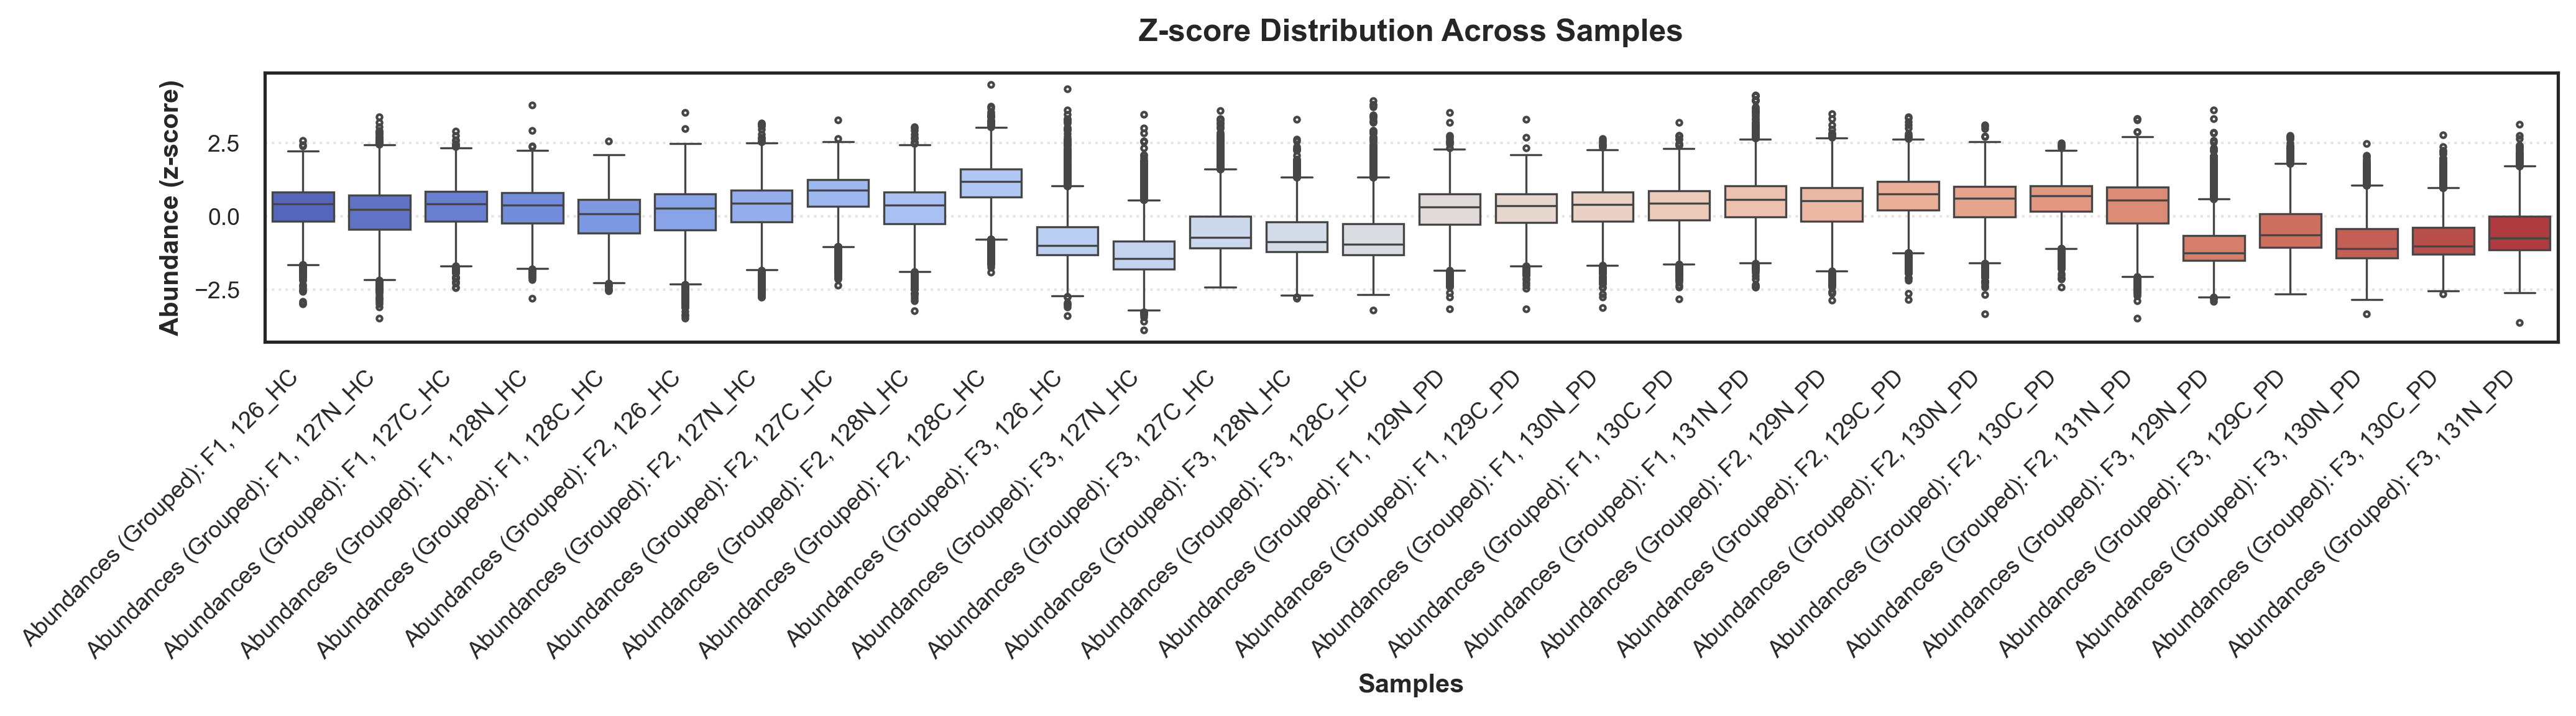

Performing differential expression analysis...
Generating Volcano plot...


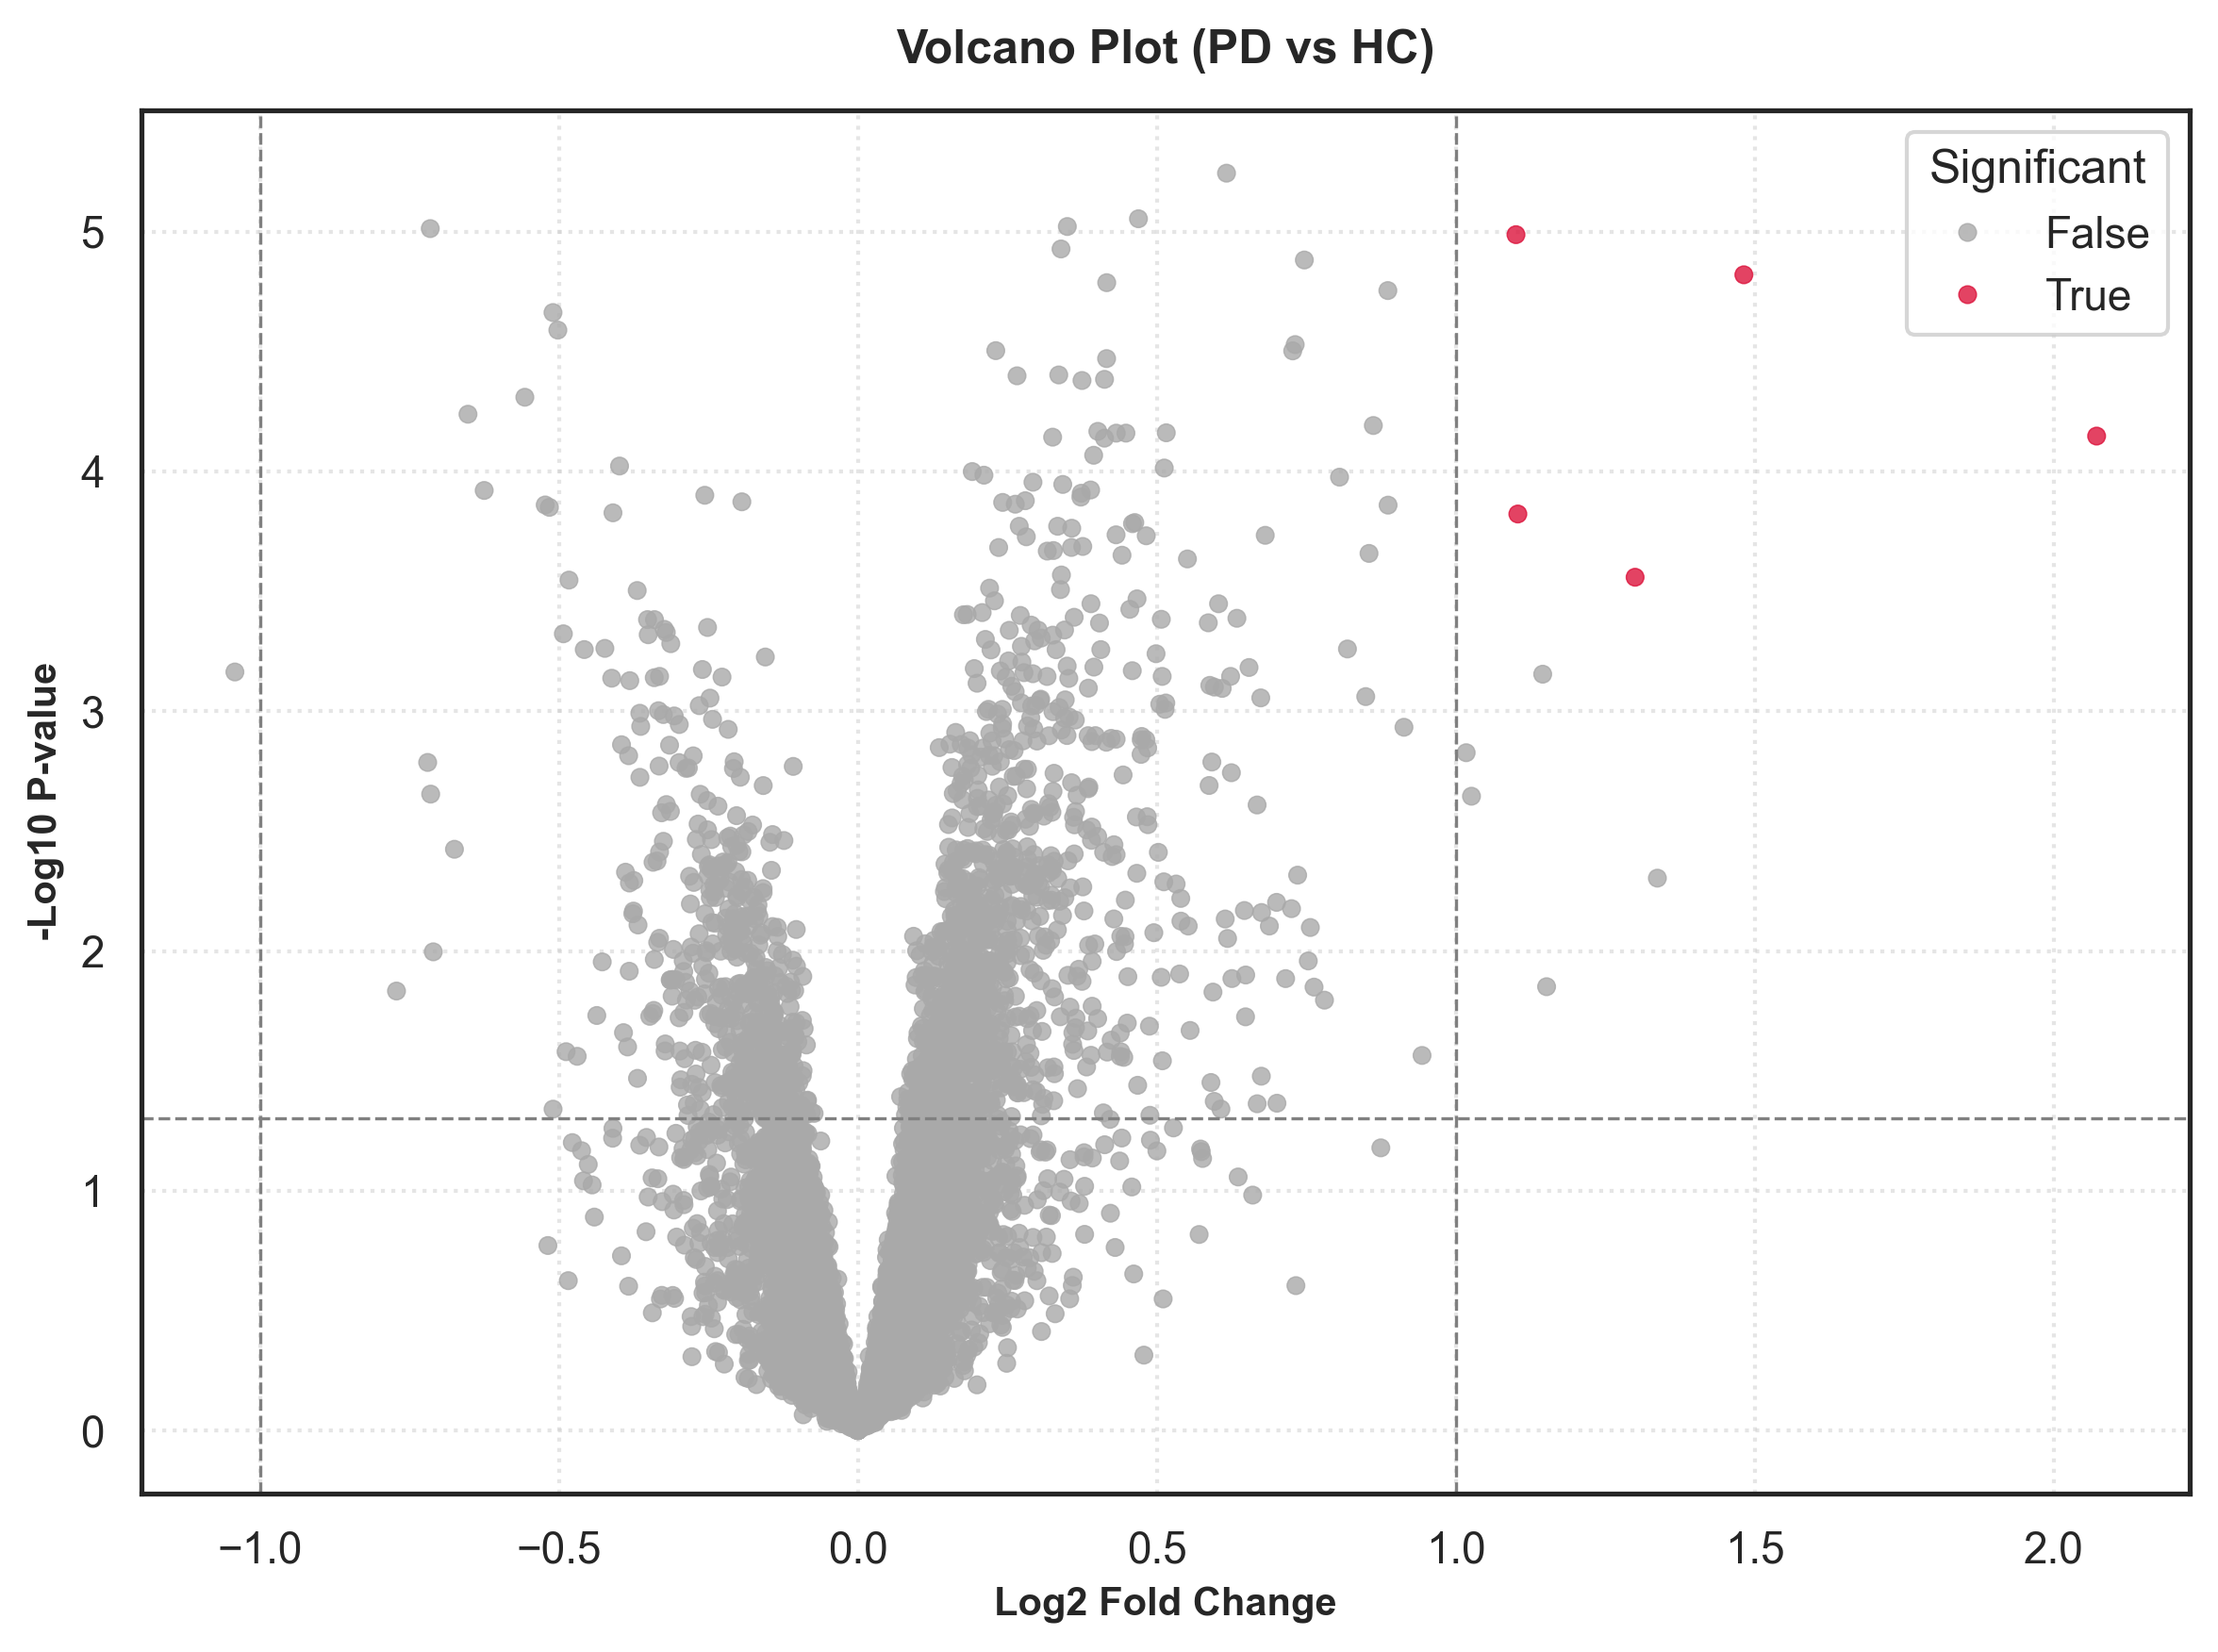

Running PCA on samples...


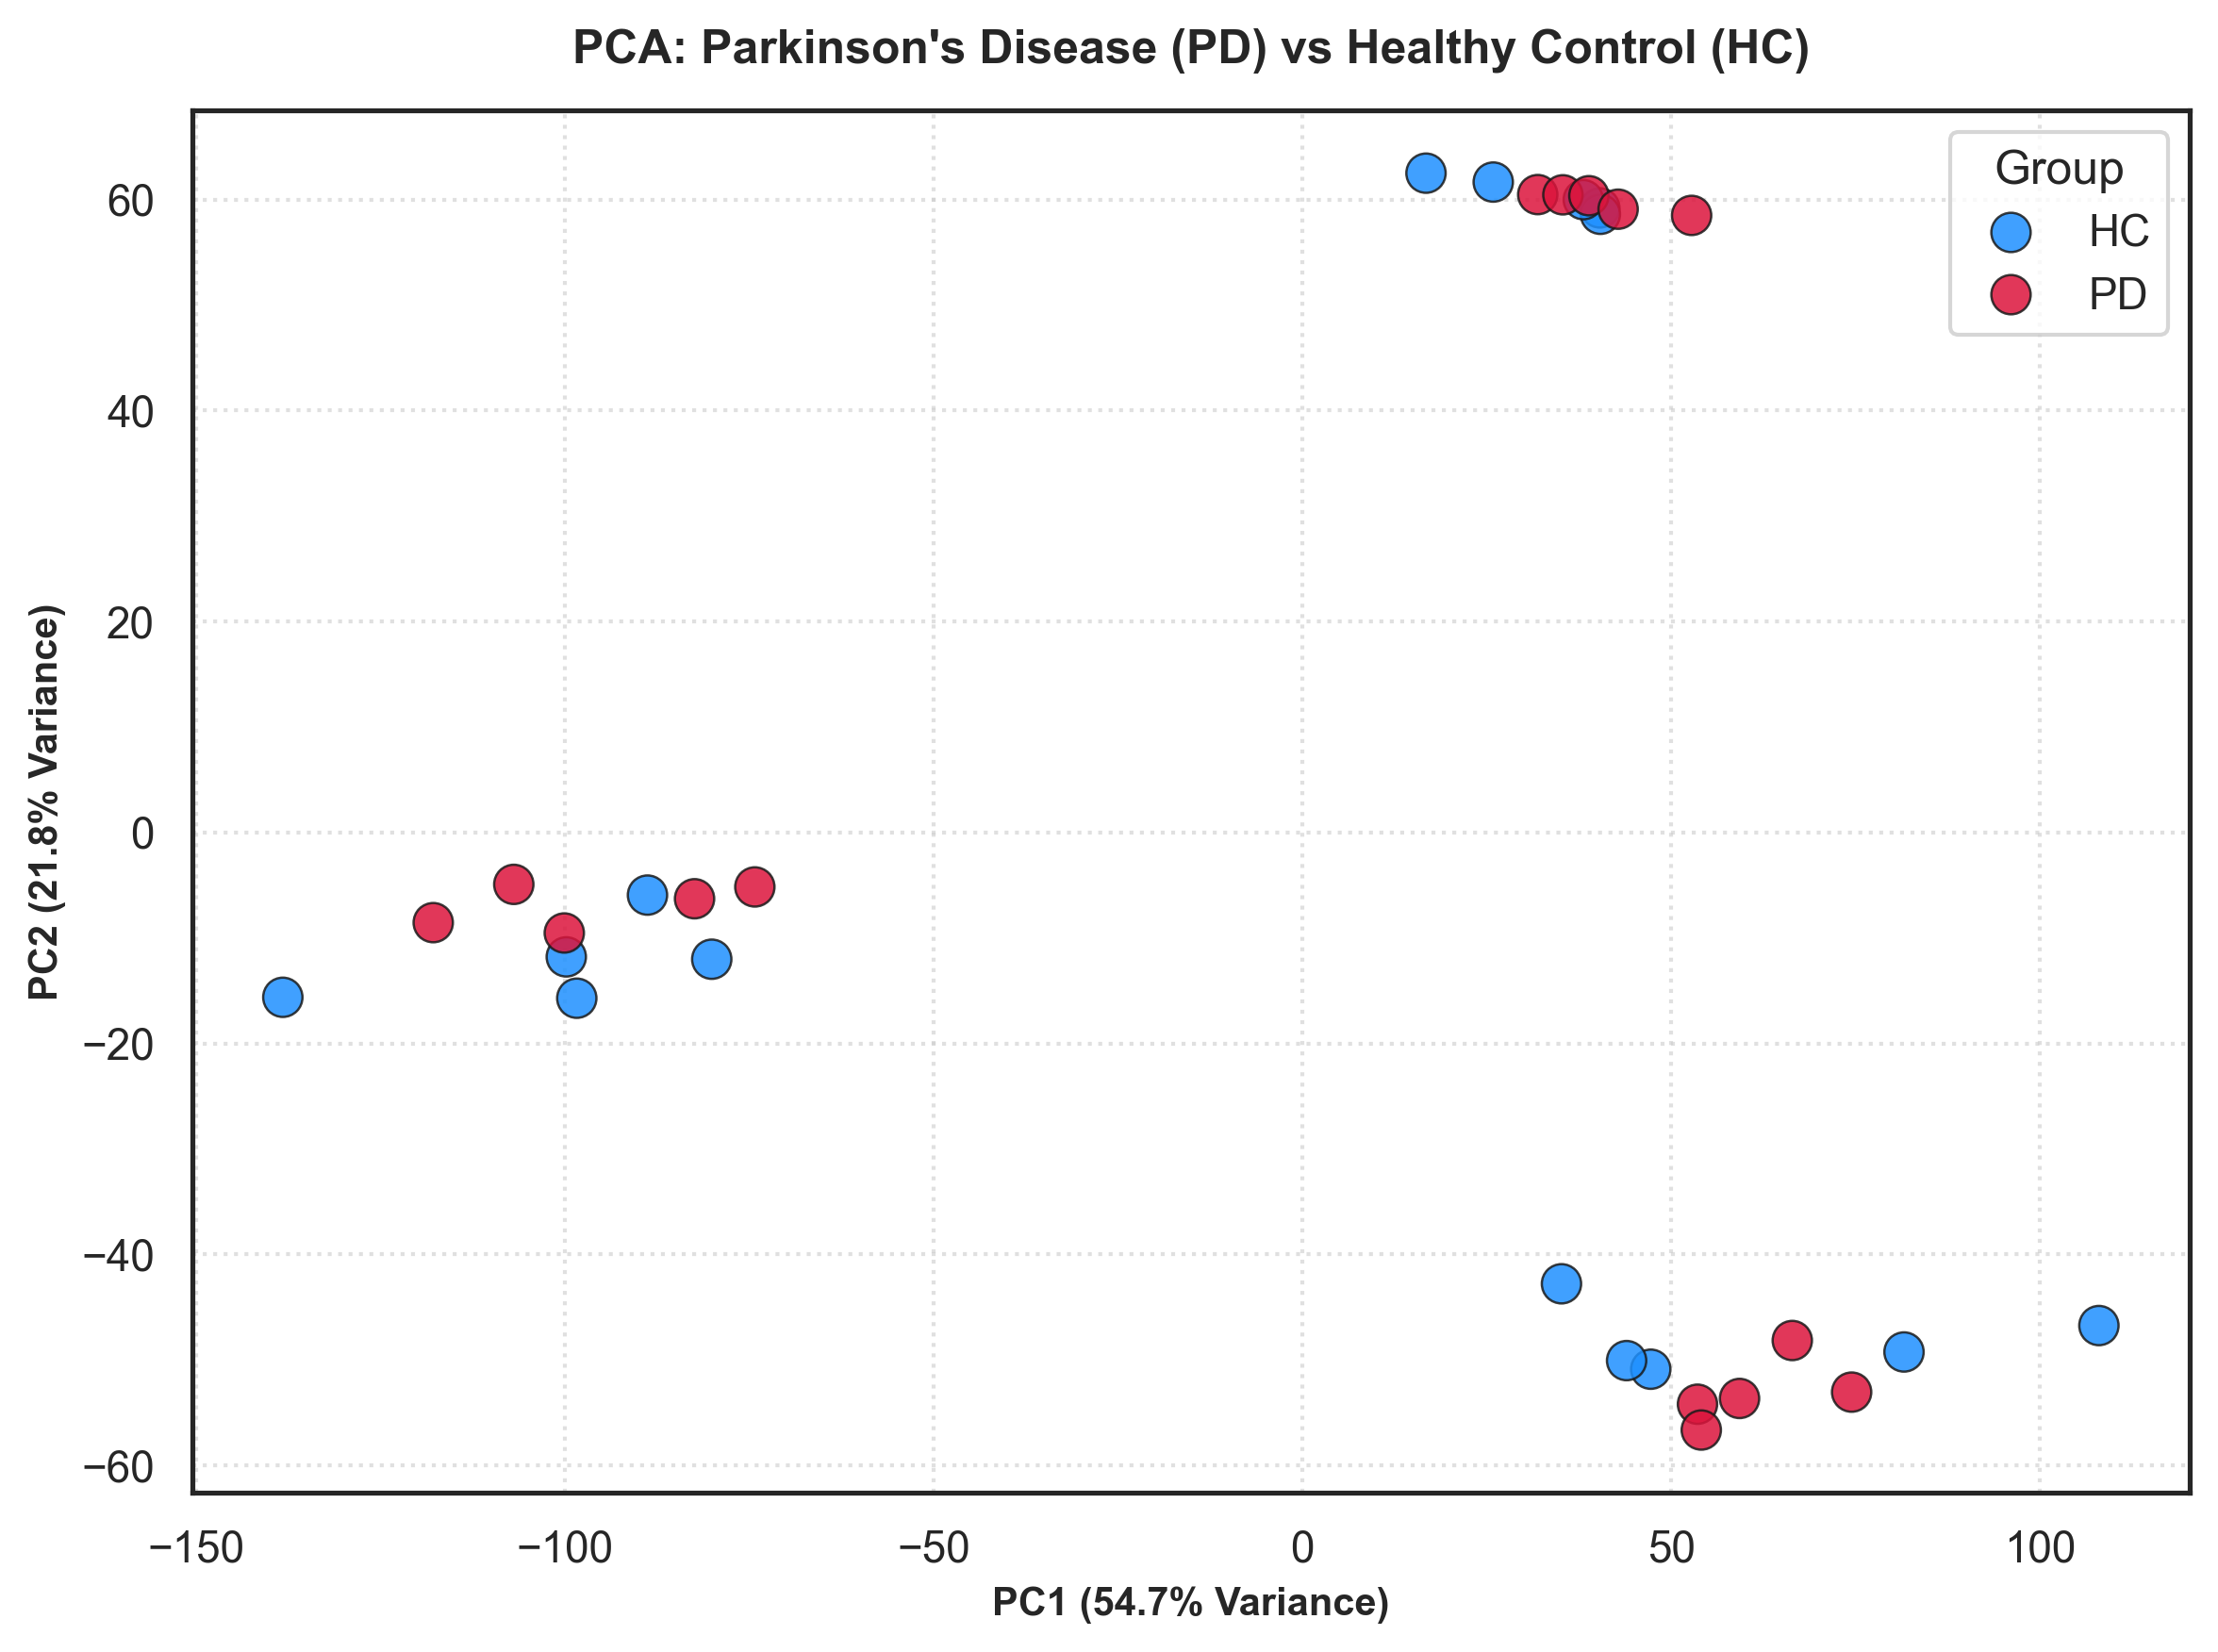

Running PCA on proteins...


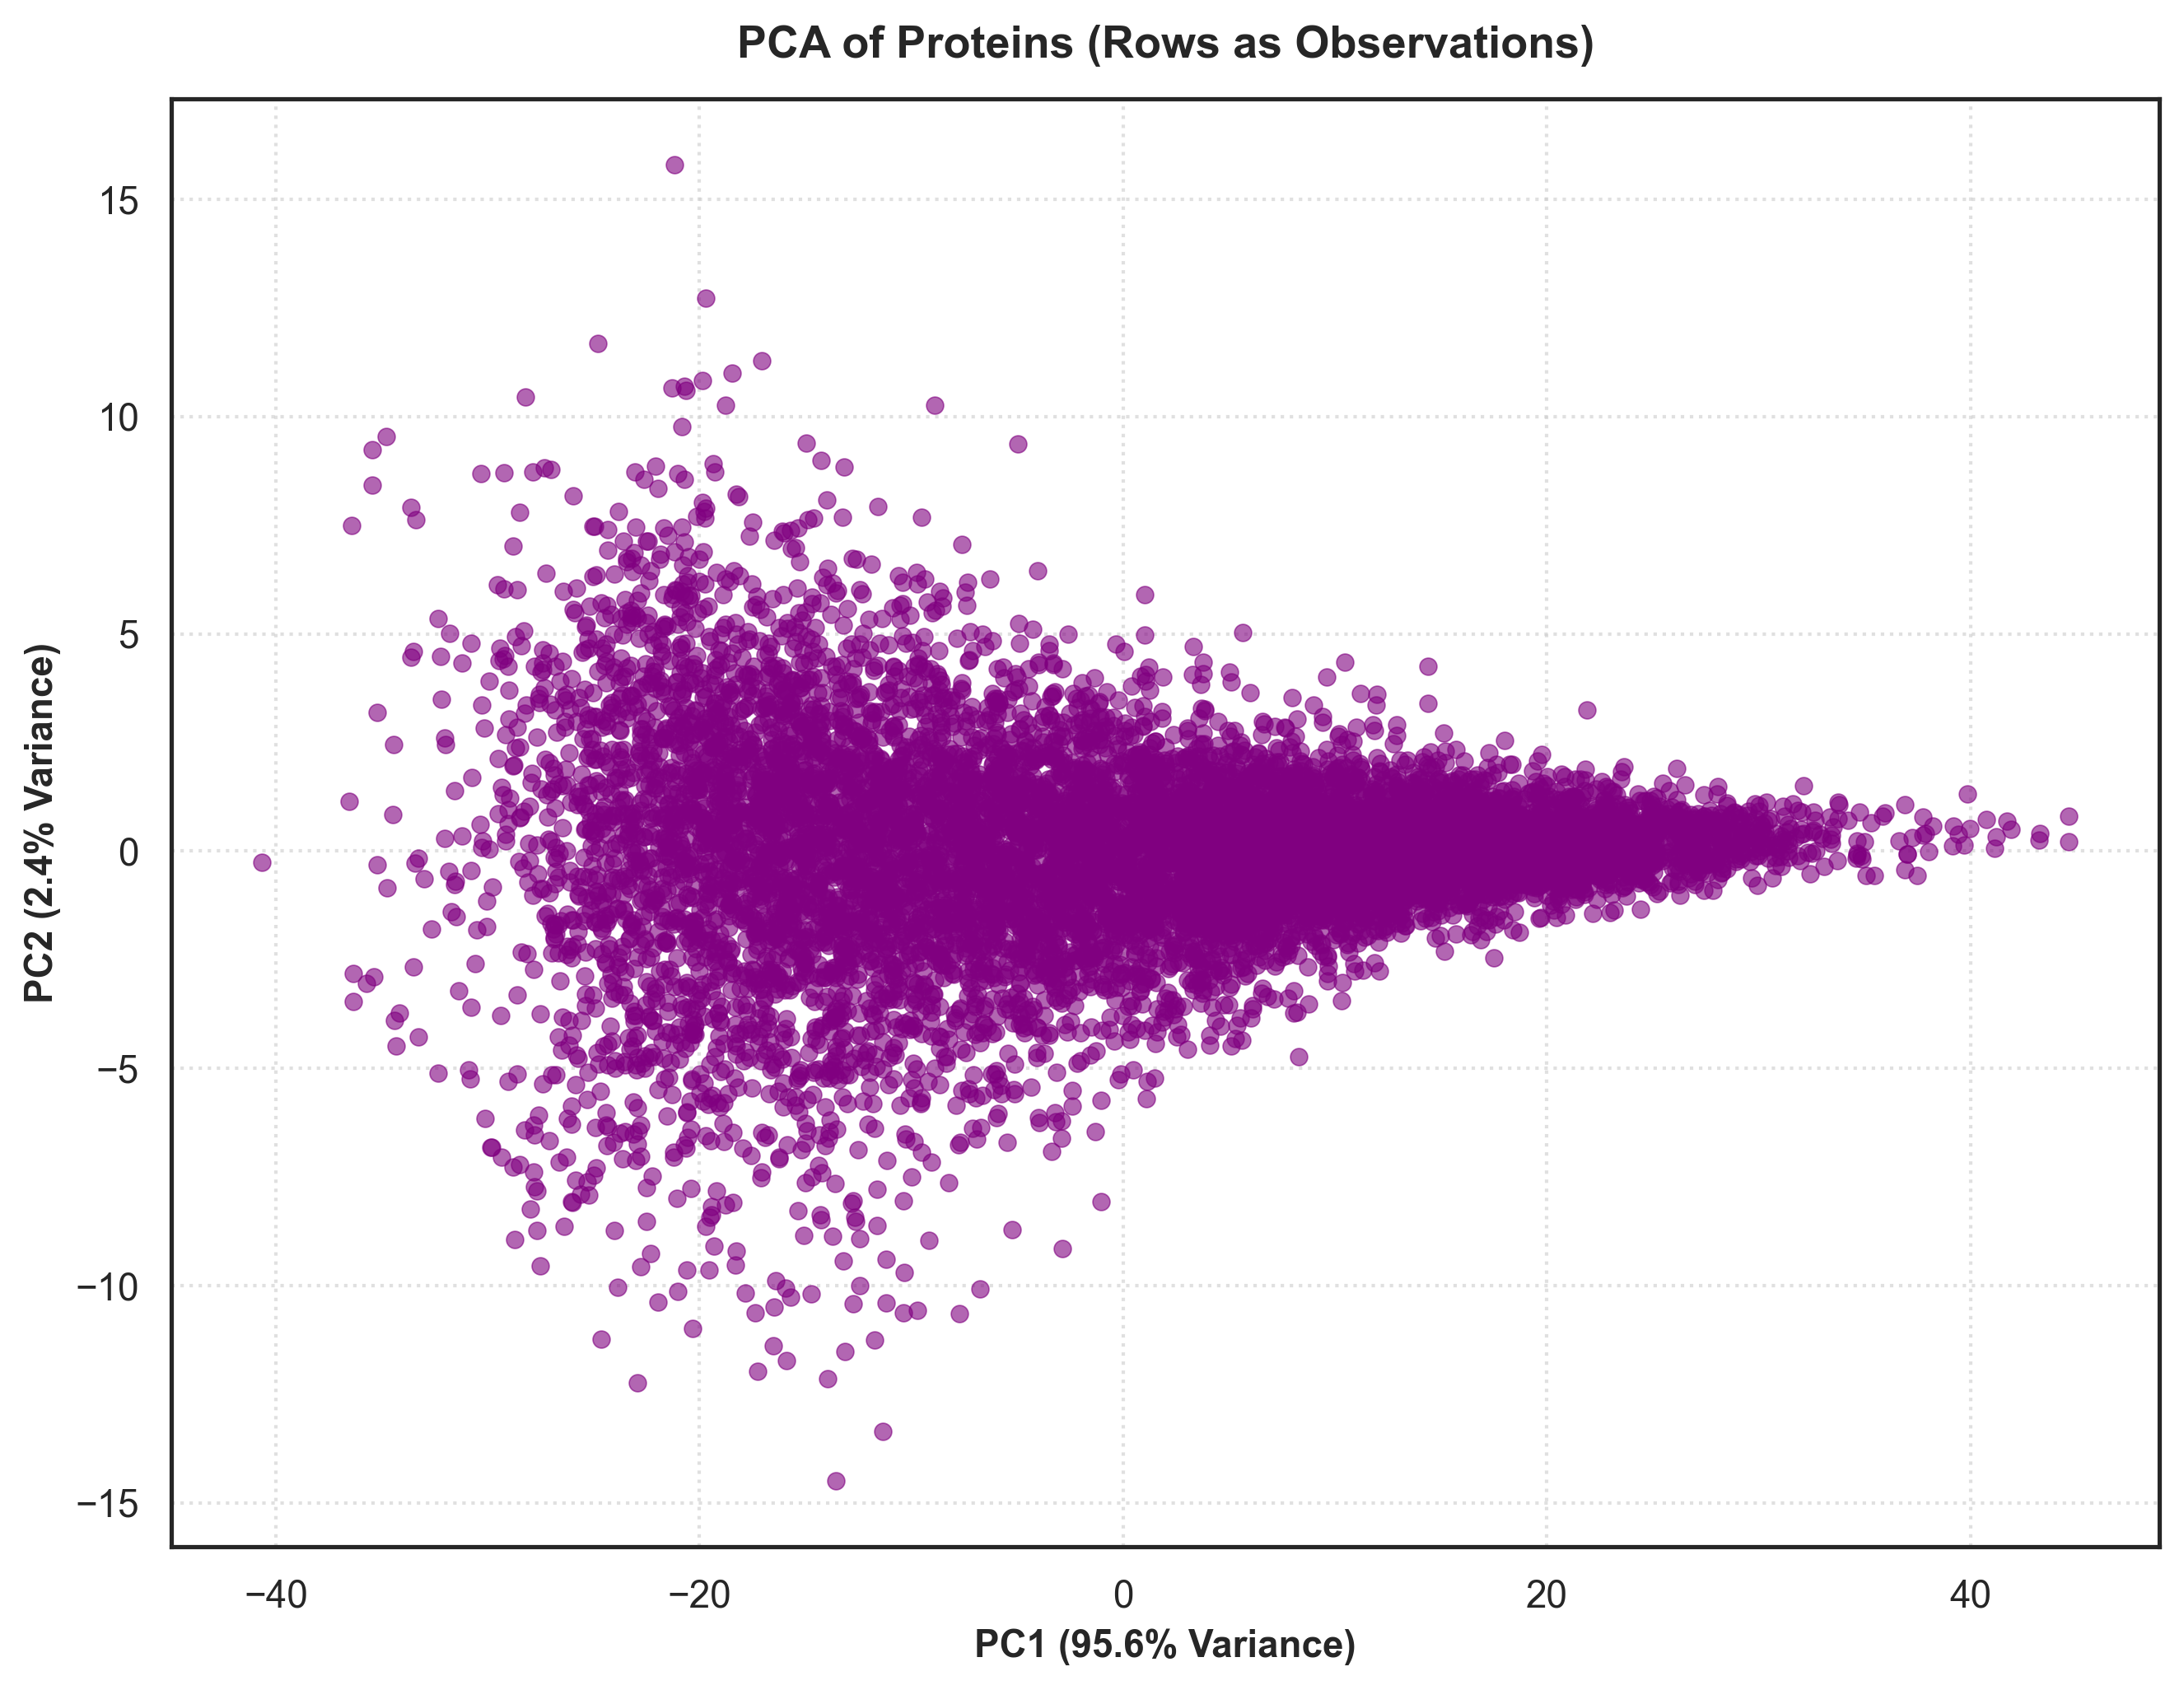

Running UMAP analysis on samples...


C:\Users\Anas\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


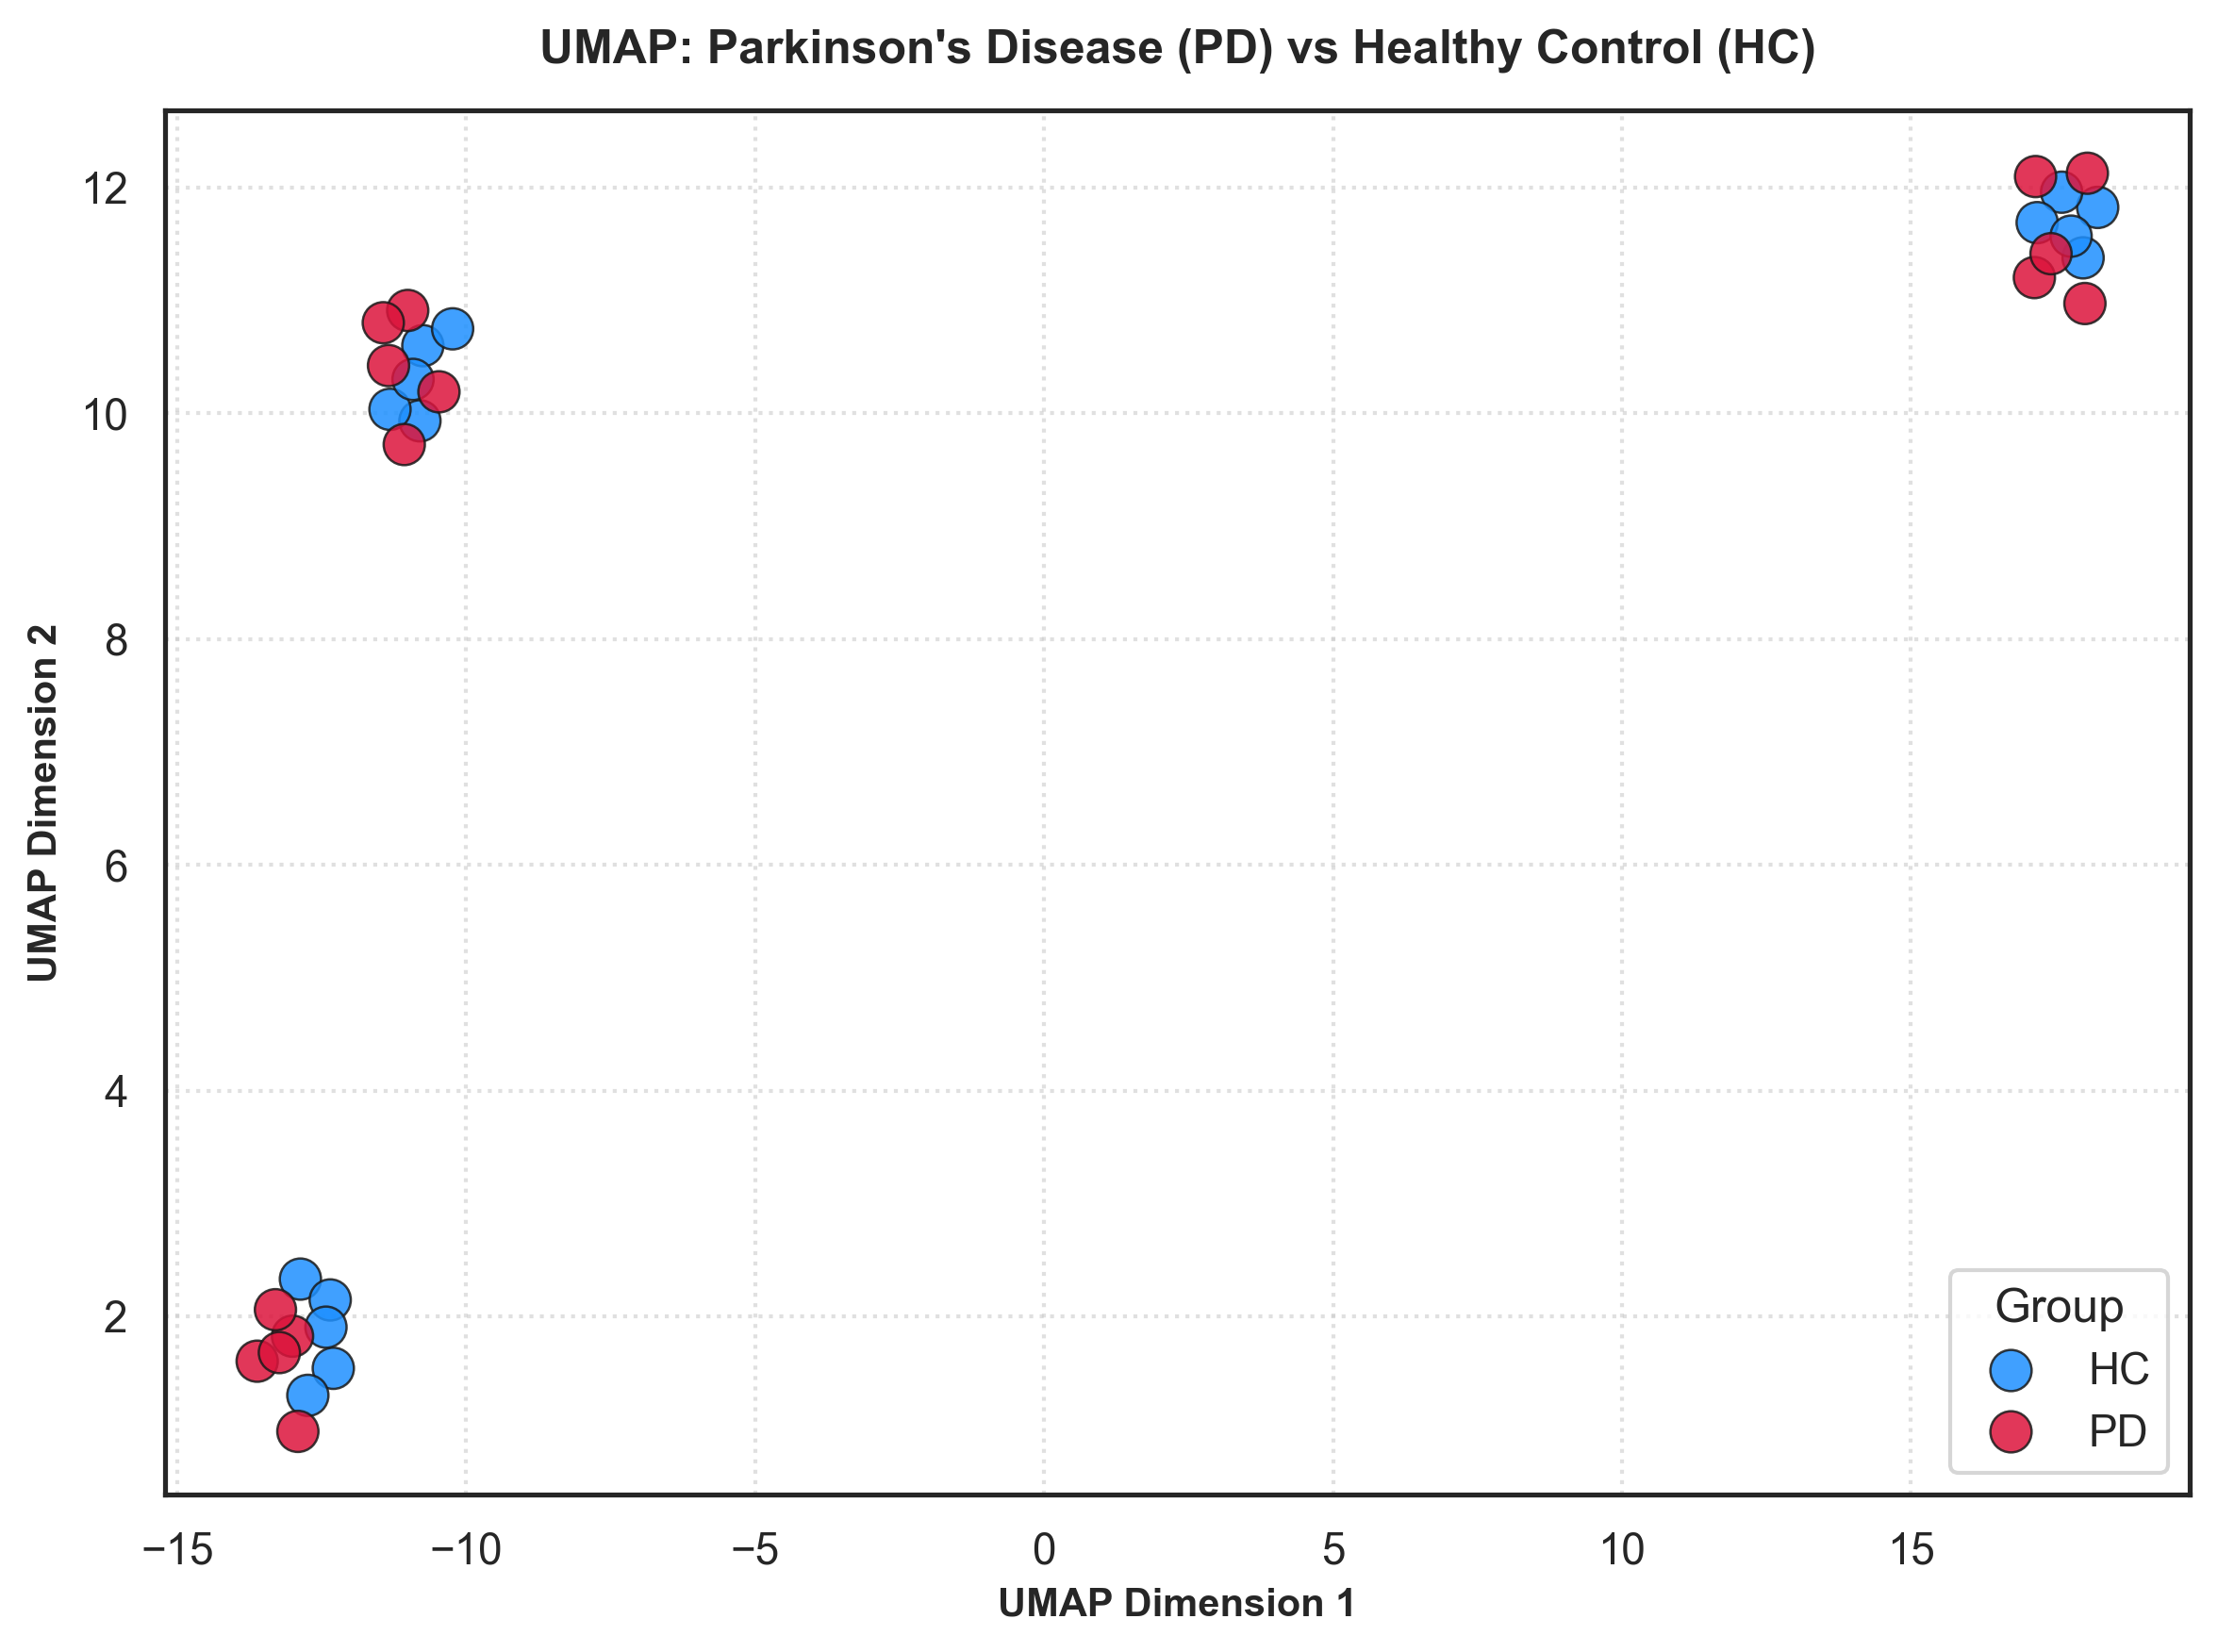

Running UMAP analysis on proteins...


C:\Users\Anas\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


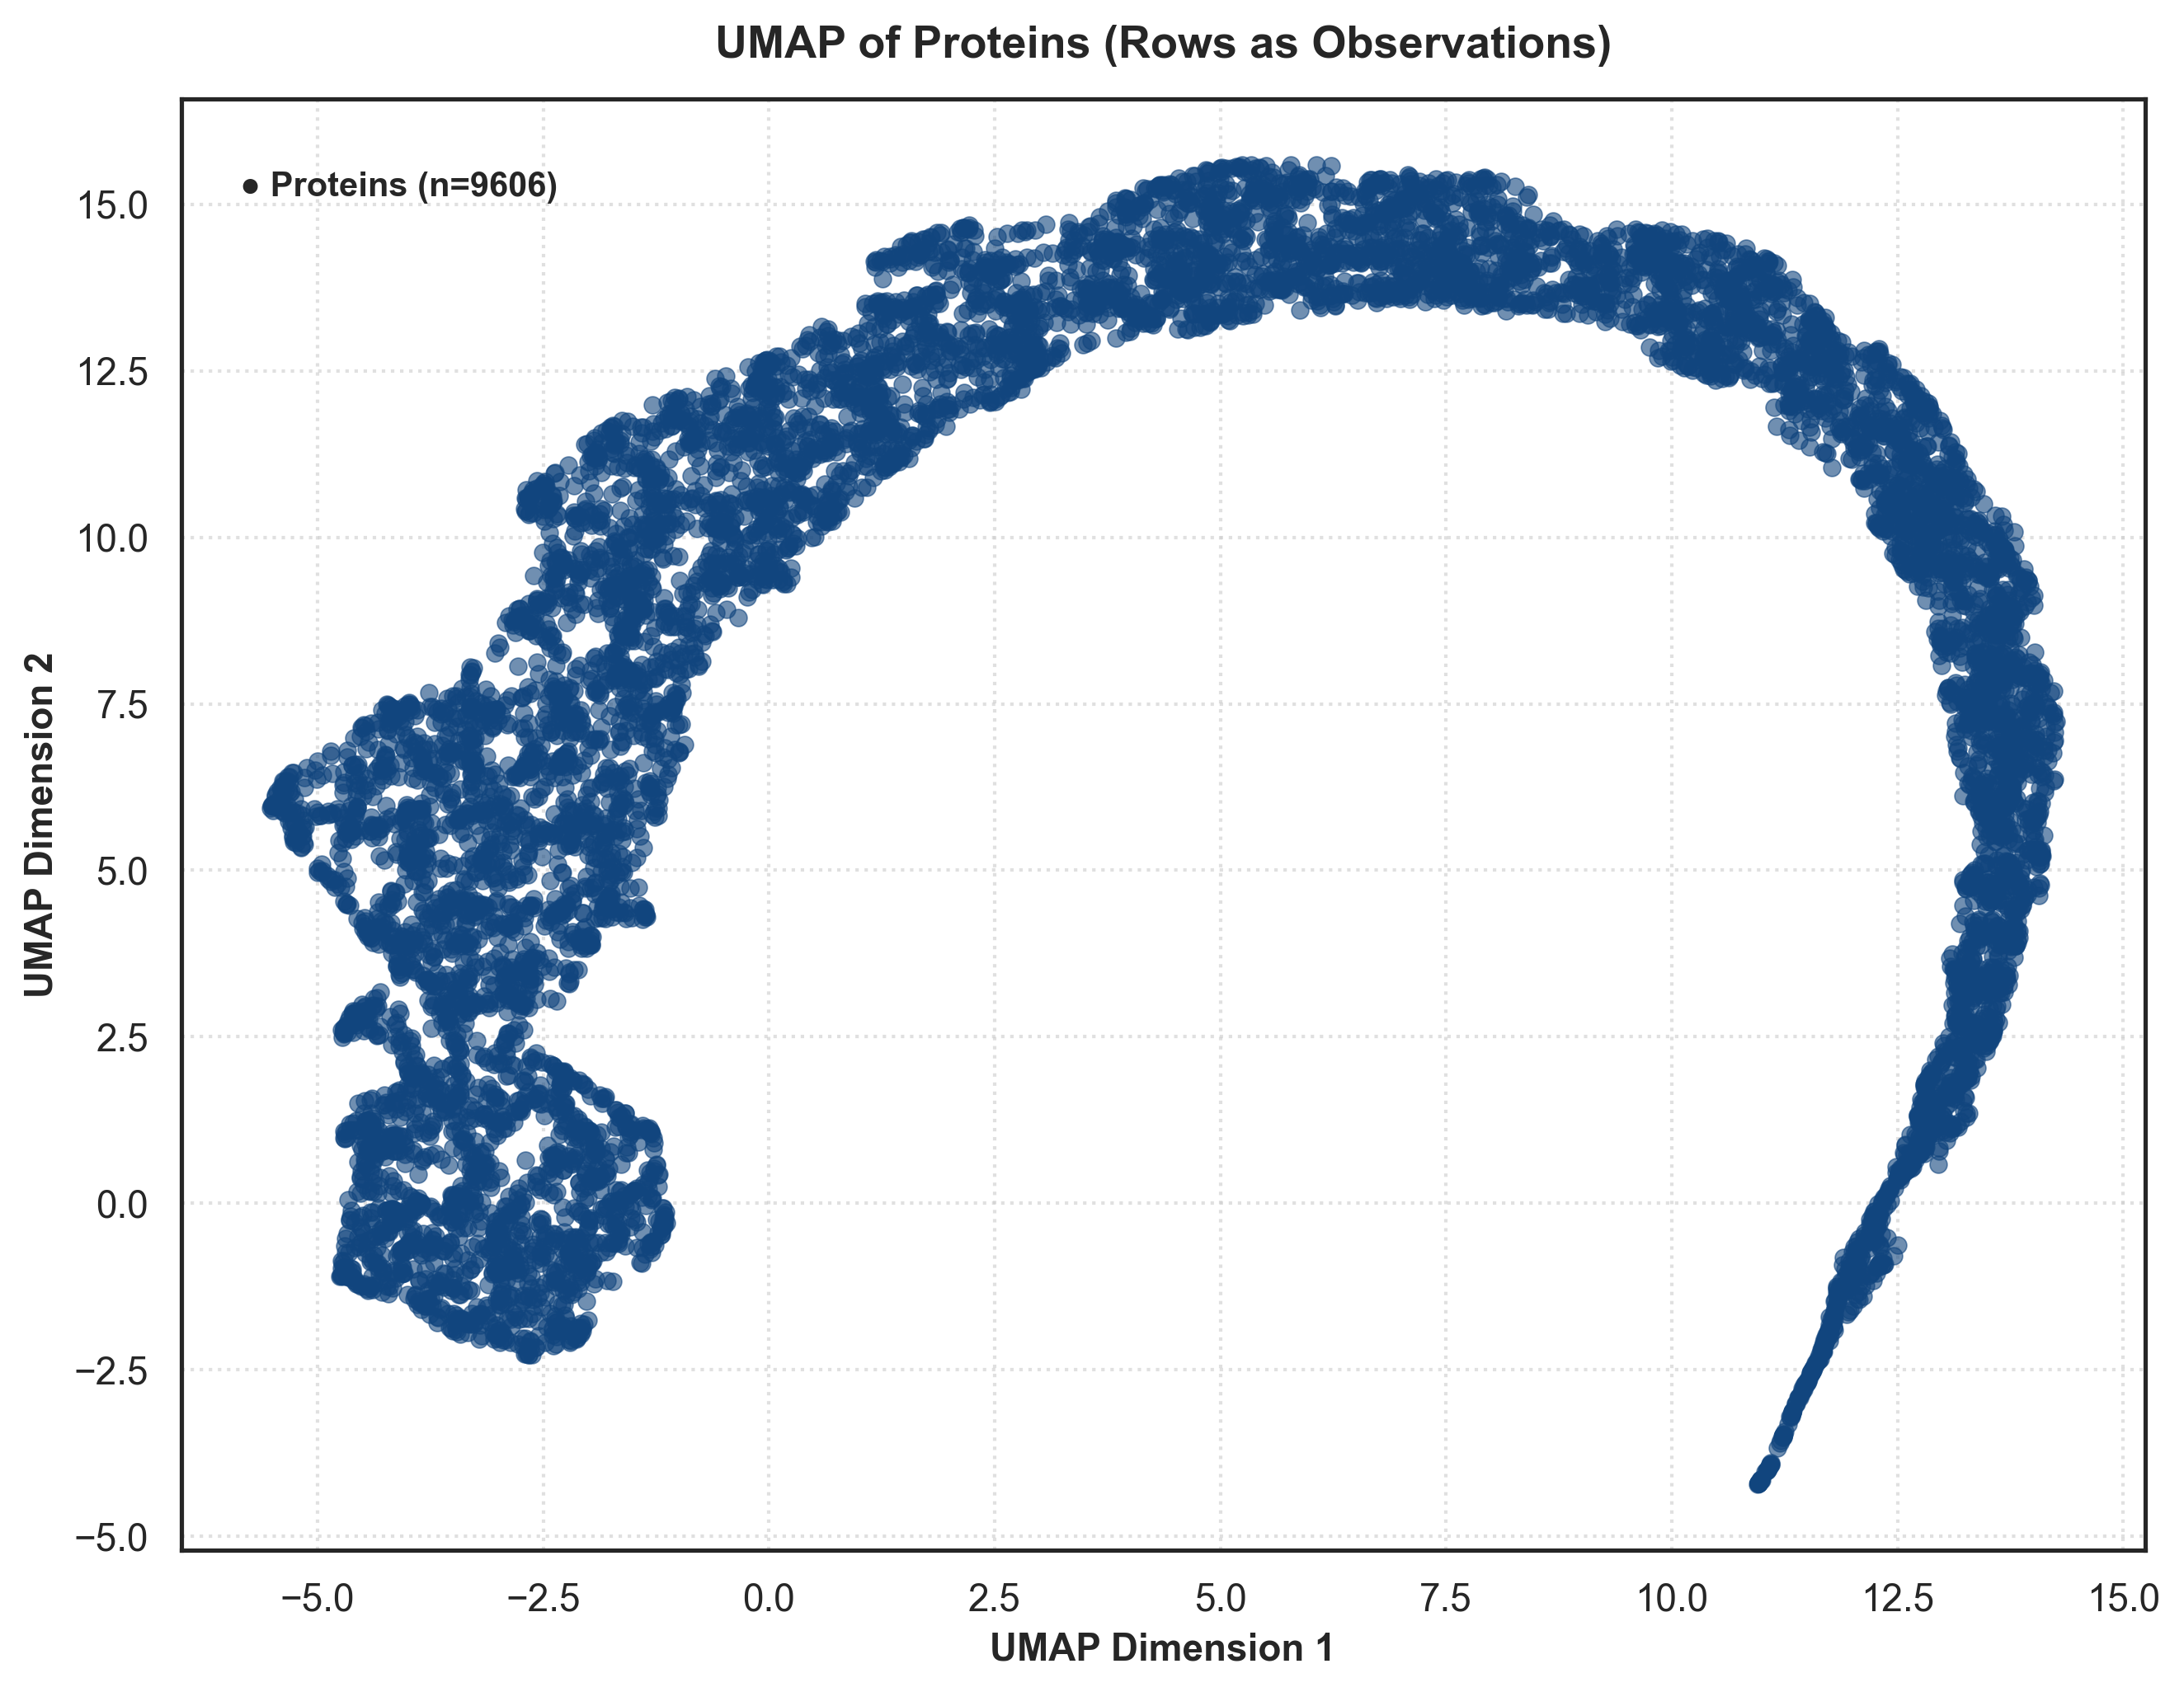

Generating Mean Abundance vs Variance plot...


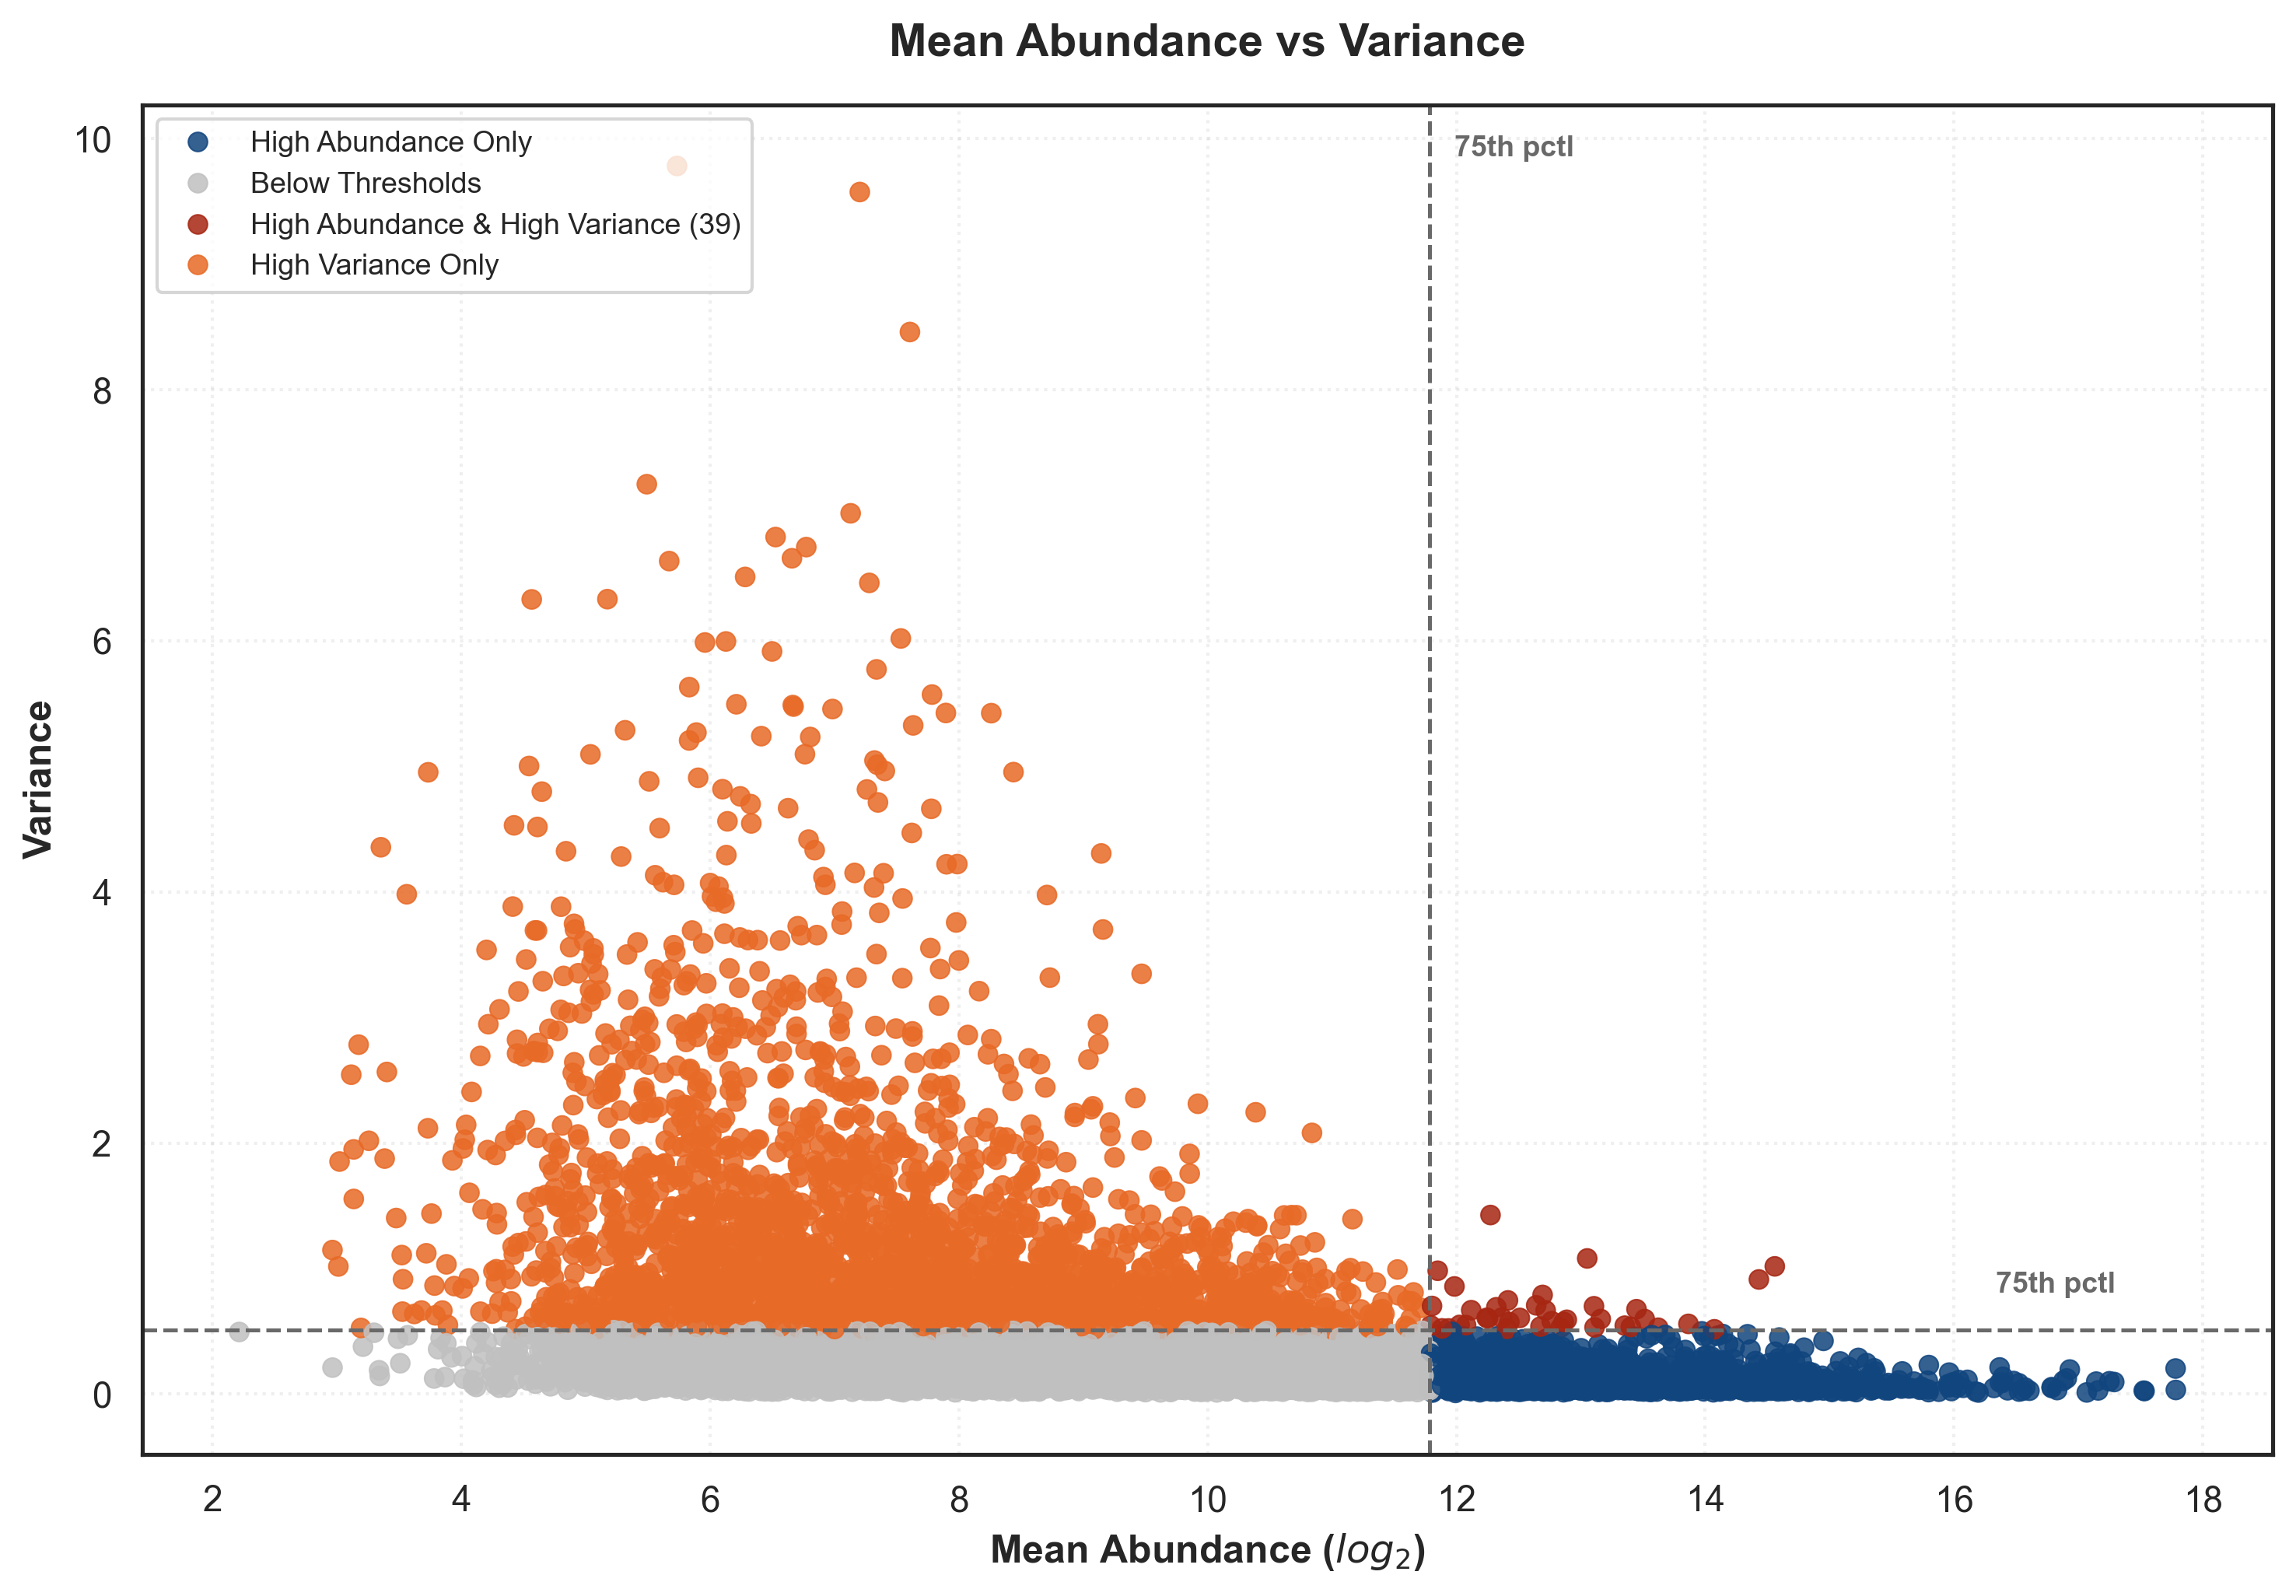

Running automated machine learning benchmarks across 6 models...
Generating sorted ROC curves...


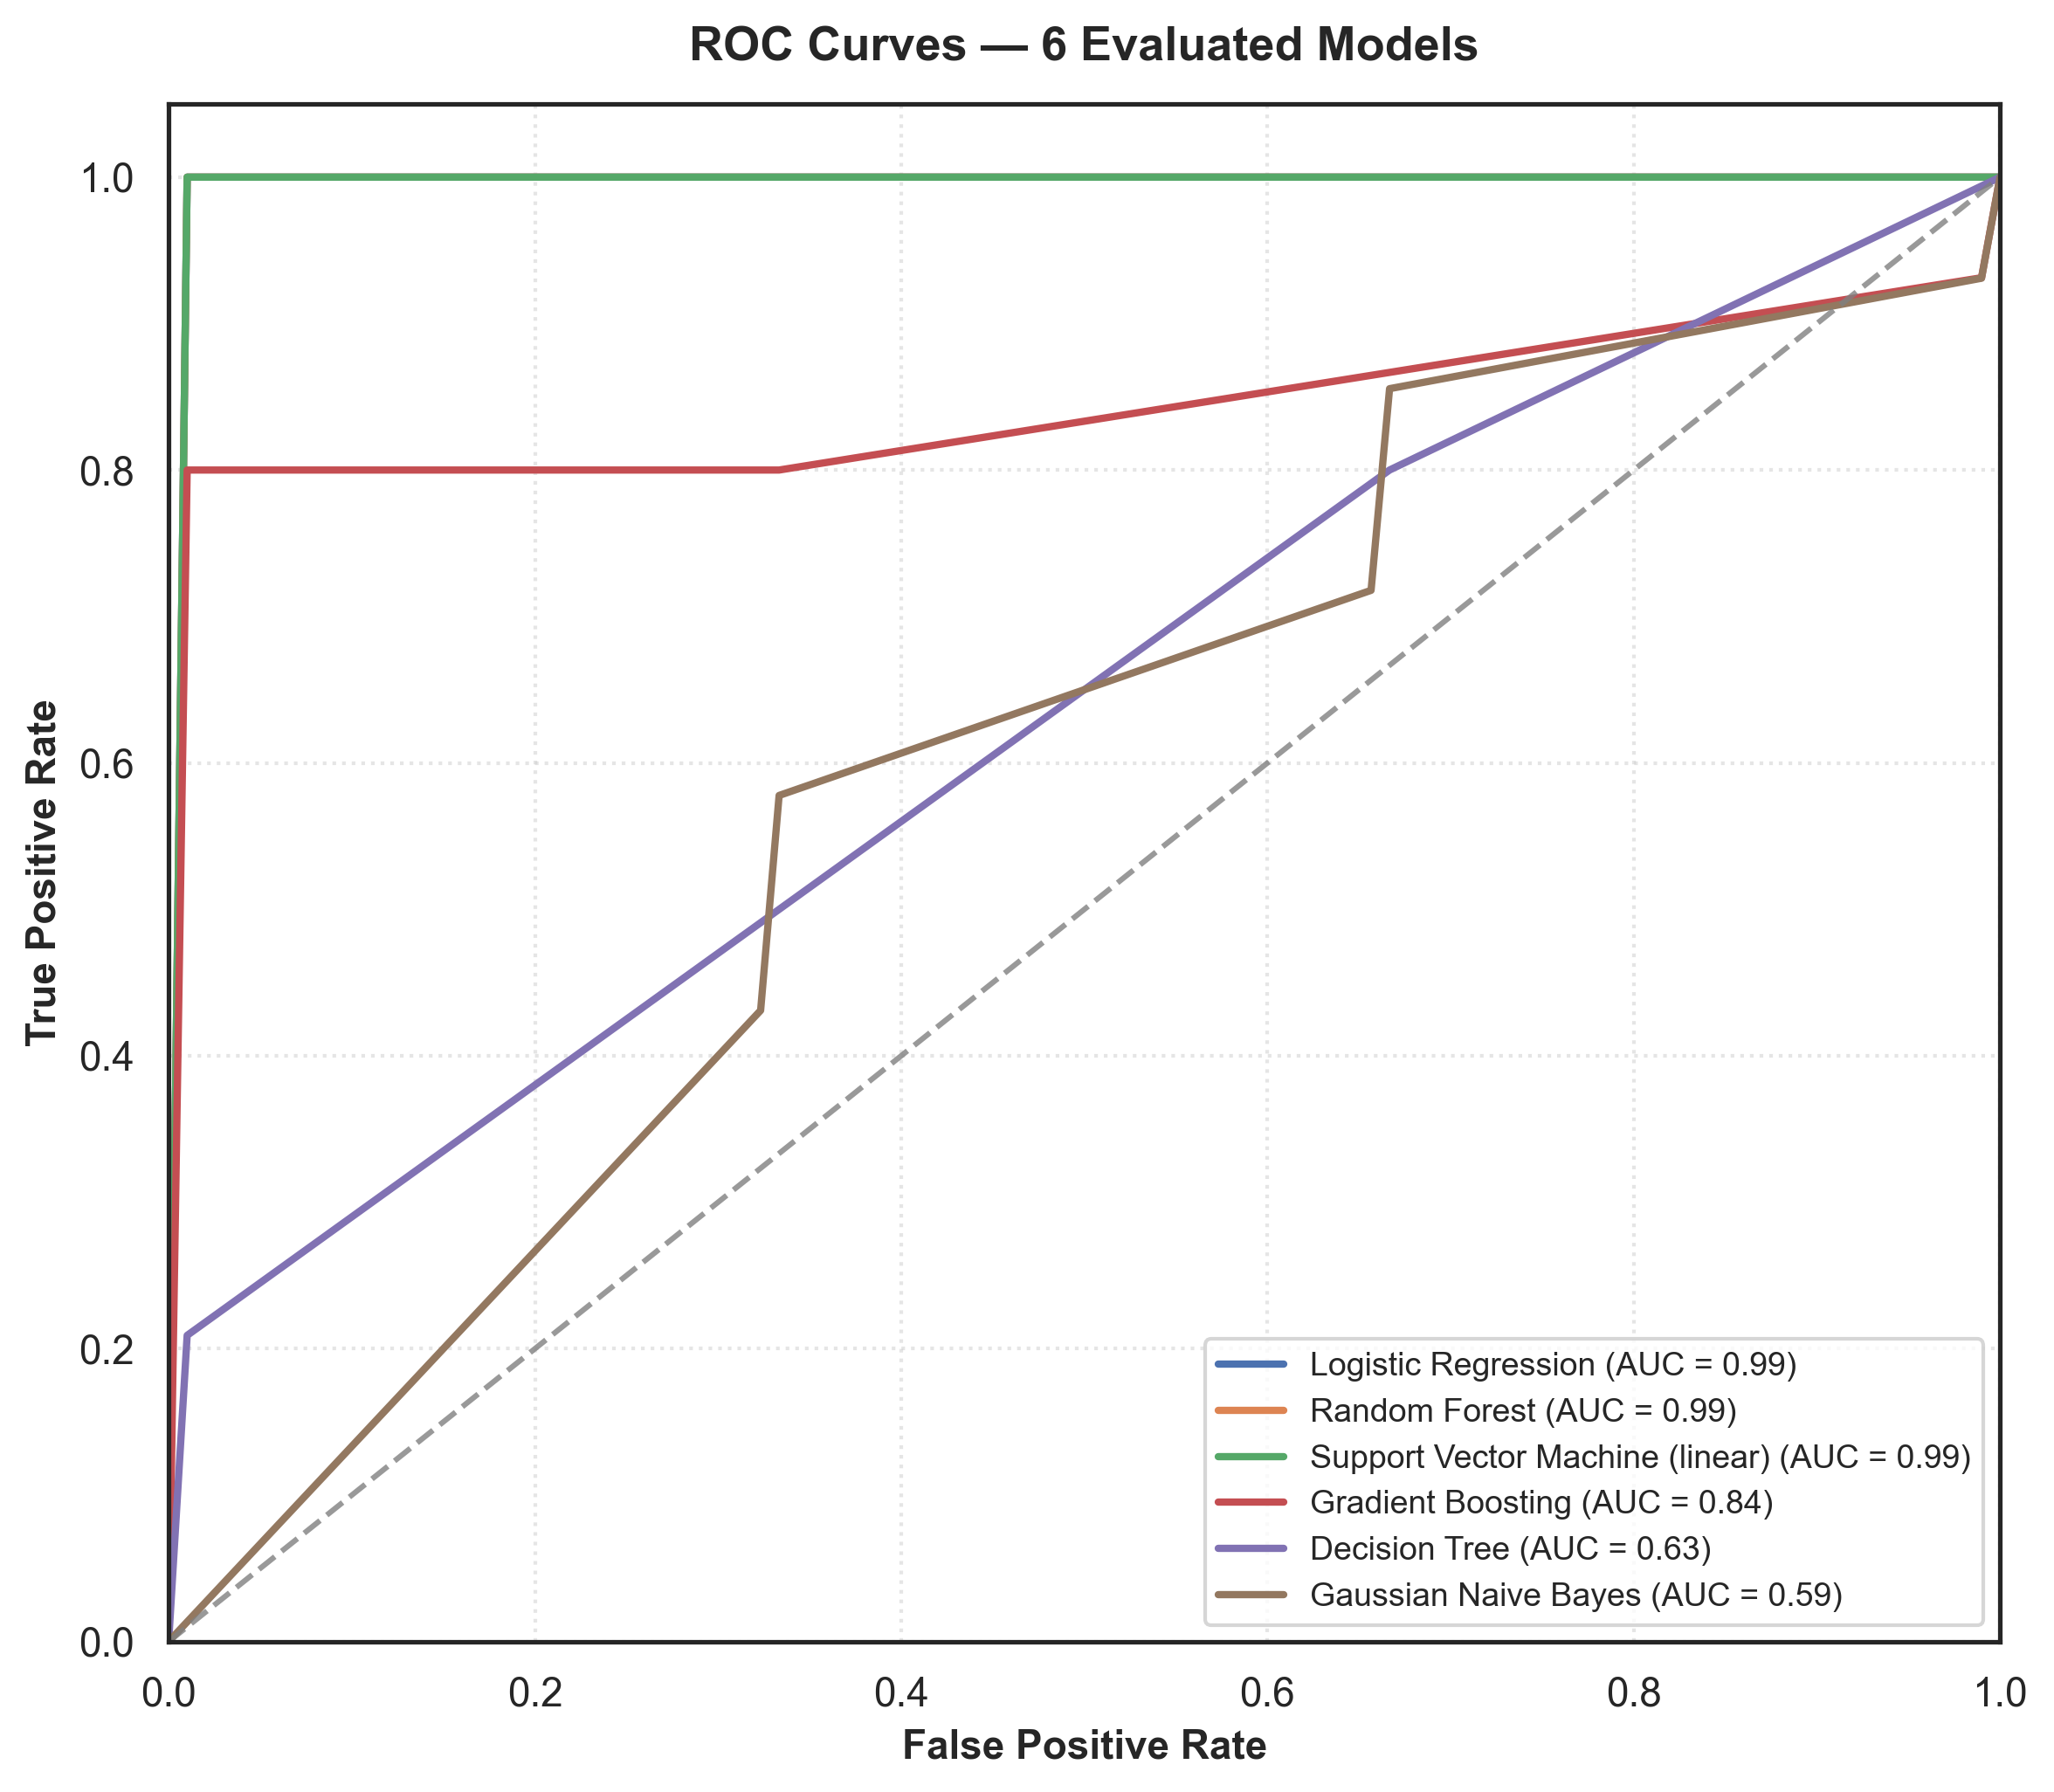

Generating Confusion Matrices...


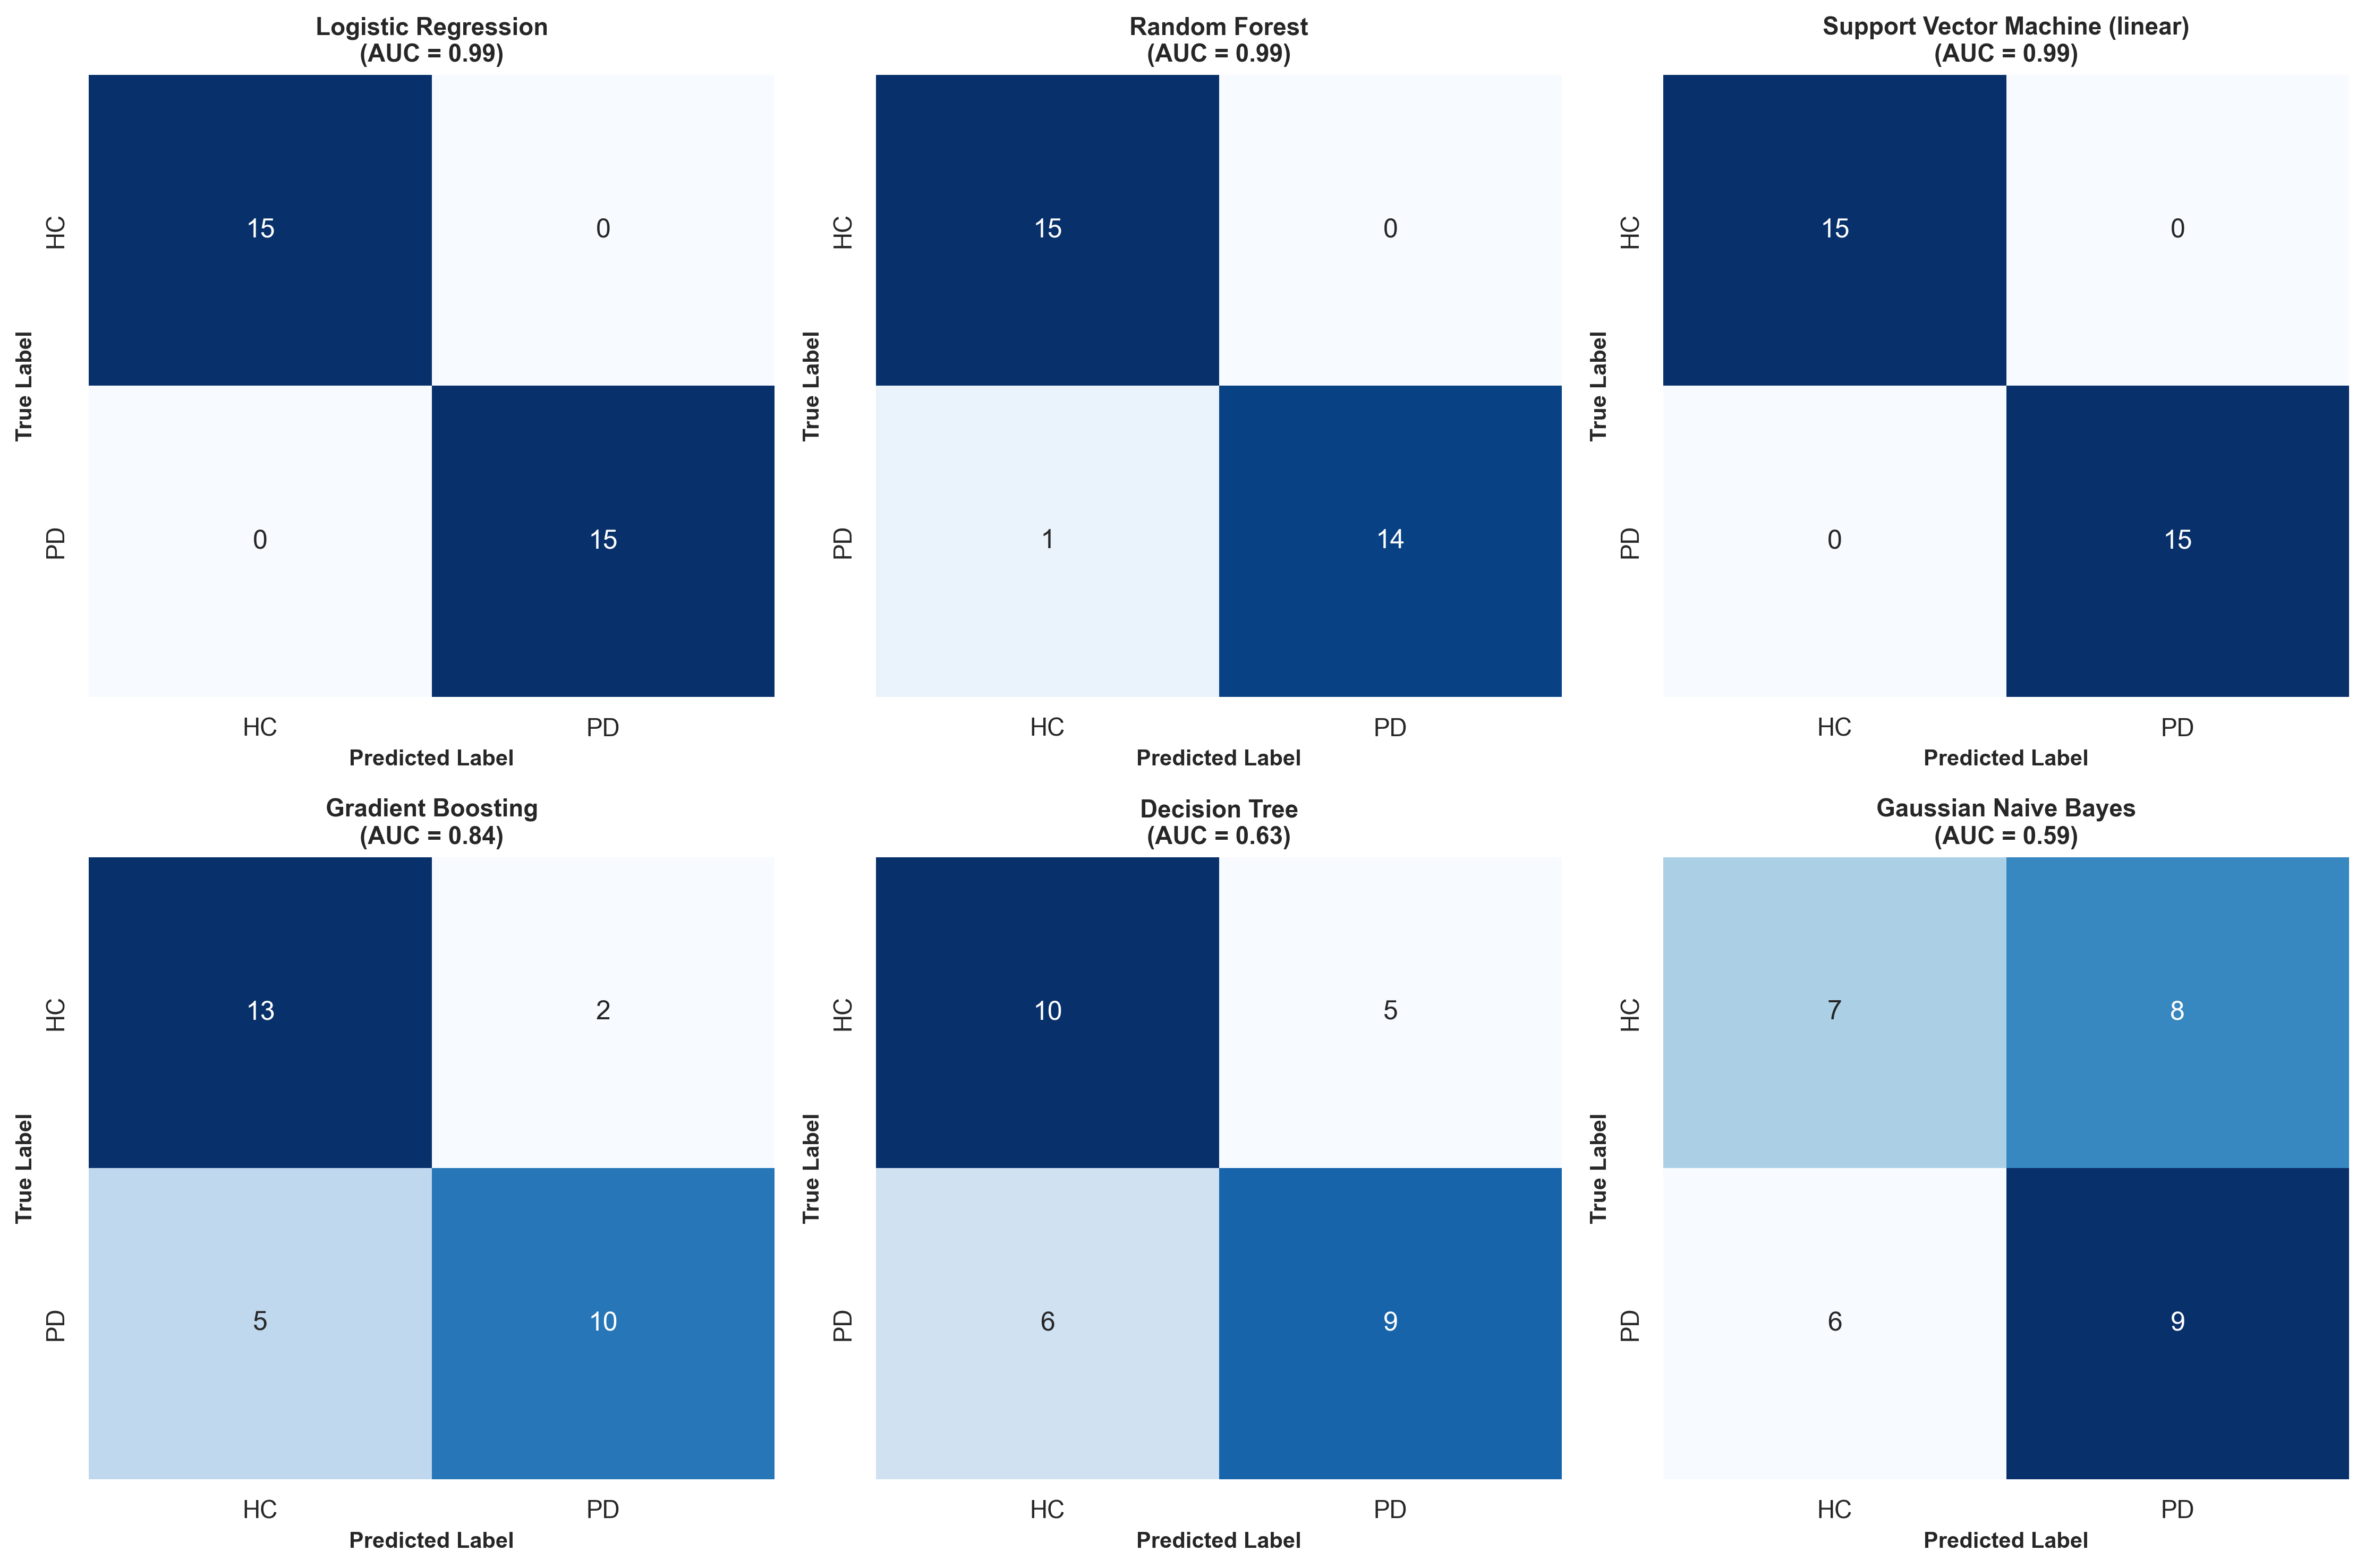


--- Automated Machine Learning Performance Summary ---
                          Model   AUC Accuracy Sensitivity Specificity    F1
            Logistic Regression 0.995   100.0%      100.0%      100.0% 1.000
                  Random Forest 0.995    96.7%       93.3%      100.0% 0.966
Support Vector Machine (linear) 0.995   100.0%      100.0%      100.0% 1.000
              Gradient Boosting 0.841    76.7%       66.7%       86.7% 0.741
                  Decision Tree 0.632    63.3%       60.0%       66.7% 0.621
           Gaussian Naive Bayes 0.591    53.3%       60.0%       46.7% 0.562

All pipeline figures and summaries successfully completed and saved in 'benchmarks/'.


In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc, accuracy_score, f1_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
import umap

def run_comprehensive_proteomics_pipeline(file_path, output_dir="benchmarks"):
    os.makedirs(output_dir, exist_ok=True)
    
    print("Loading and preprocessing data...")
    df = pd.read_excel(file_path, sheet_name="ProteinTable")
    
    abundance_cols = [c for c in df.columns if 'Abundances (Grouped):' in c]
    hc_cols = [c for c in abundance_cols if 'HC' in c]
    pd_cols = [c for c in abundance_cols if 'PD' in c]
    all_sample_cols = hc_cols + pd_cols

    missing_ratio = df[all_sample_cols].isna().mean(axis=1)
    df_filtered = df[missing_ratio <= 0.90].copy()

    print("Imputing missing values with KNN (k=5)...")
    imputer = KNNImputer(n_neighbors=5)
    df_filtered[all_sample_cols] = imputer.fit_transform(df_filtered[all_sample_cols])

    print("Applying Log2 transformation...")
    log2_data = np.log2(df_filtered[all_sample_cols].replace(0, np.nan))
    log2_data = log2_data.fillna(log2_data.min().min())

    row_mean = log2_data[all_sample_cols].mean(axis=1)
    row_std = log2_data[all_sample_cols].std(axis=1)
    z_row_wise = log2_data[all_sample_cols].sub(row_mean, axis=0).div(row_std, axis=0)

    print("Generating Z-score distribution boxplot...")
    plt.figure(figsize=(14, 4), dpi=300)
    sns.set_theme(style="white")
    sns.boxplot(data=z_row_wise, palette="coolwarm", fliersize=2, linewidth=0.8)
    plt.title("Z-score Distribution Across Samples", fontsize=12, fontweight='bold', pad=12)
    plt.xlabel("Samples", fontsize=10, fontweight='bold')
    plt.ylabel("Abundance (z-score)", fontsize=10, fontweight='bold')
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.yticks(fontsize=9)
    plt.grid(axis='y', linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "zscore_distribution_tool_match.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Performing differential expression analysis...")
    hc_matrix = log2_data[hc_cols].values
    pd_matrix = log2_data[pd_cols].values
    p_values = []
    log2_fc = []
    for i in range(len(log2_data)):
        hc_vals = hc_matrix[i]
        pd_vals = pd_matrix[i]
        stat, pval = ttest_rel(pd_vals, hc_vals, nan_policy='omit')
        p_values.append(pval if not np.isnan(pval) else 1.0)
        log2_fc.append(np.mean(pd_vals) - np.mean(hc_vals))

    _, fdr_vals, _, _ = multipletests(p_values, method='fdr_bh')
    volcano_df = pd.DataFrame({
        'Gene Symbol': df_filtered['Gene Symbol'].values,
        'Accession': df_filtered['Accession'].values,
        'Log2FC': log2_fc,
        'P-value': p_values,
        'FDR': fdr_vals
    })
    volcano_df['NegLog10P'] = -np.log10(volcano_df['P-value'].replace(0, 1e-300))
    volcano_df['Significant'] = (volcano_df['FDR'] < 0.05) & (volcano_df['Log2FC'].abs() > 1)

    print("Generating Volcano plot...")
    plt.figure(figsize=(8, 6), dpi=300)
    sns.scatterplot(
        data=volcano_df, x='Log2FC', y='NegLog10P', hue='Significant',
        palette={True: 'crimson', False: 'darkgray'}, s=20, alpha=0.8, edgecolor=None
    )
    plt.axhline(-np.log10(0.05), color='grey', linestyle='--', linewidth=0.8)
    plt.axvline(-1, color='grey', linestyle='--', linewidth=0.8)
    plt.axvline(1, color='grey', linestyle='--', linewidth=0.8)
    plt.title("Volcano Plot (PD vs HC)", fontsize=12, fontweight='bold', pad=12)
    plt.xlabel("Log2 Fold Change", fontsize=10, fontweight='bold')
    plt.ylabel("-Log10 P-value", fontsize=10, fontweight='bold')
    plt.legend(title="Significant", loc='upper right', frameon=True)
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "volcano_plot.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Running PCA on samples...")
    X_samples = log2_data[all_sample_cols].T.values
    scaler = StandardScaler()
    X_samples_scaled = scaler.fit_transform(X_samples)
    pca_samples = PCA(n_components=2)
    sample_pcs = pca_samples.fit_transform(X_samples_scaled)
    sample_var = pca_samples.explained_variance_ratio_ * 100
    sample_pca_df = pd.DataFrame(data=sample_pcs, columns=['PC1', 'PC2'])
    sample_pca_df['Sample'] = all_sample_cols
    sample_pca_df['Group'] = ['HC' if 'HC' in col else 'PD' for col in all_sample_cols]

    plt.figure(figsize=(8, 6), dpi=300)
    sns.scatterplot(
        data=sample_pca_df, x='PC1', y='PC2', hue='Group',
        palette={'HC': 'dodgerblue', 'PD': 'crimson'}, s=100, alpha=0.85, edgecolor='k', linewidth=0.6
    )
    plt.title("PCA: Parkinson's Disease (PD) vs Healthy Control (HC)", fontsize=12, fontweight='bold', pad=12)
    plt.xlabel(f"PC1 ({sample_var[0]:.1f}% Variance)", fontsize=10, fontweight='bold')
    plt.ylabel(f"PC2 ({sample_var[1]:.1f}% Variance)", fontsize=10, fontweight='bold')
    plt.legend(title='Group', loc='best', frameon=True)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "pca_plot_pd_hc.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Running PCA on proteins...")
    X_proteins = log2_data[abundance_cols].values.astype(float)
    pca_proteins = PCA(n_components=2)
    protein_pcs = pca_proteins.fit_transform(X_proteins)
    protein_var = pca_proteins.explained_variance_ratio_ * 100
    pca_proteins_df = pd.DataFrame(data=protein_pcs, columns=['PC1', 'PC2'])
    pca_proteins_df['Gene Symbol'] = df_filtered['Gene Symbol'].values
    pca_proteins_df['Accession'] = df_filtered['Accession'].values

    plt.figure(figsize=(9, 7), dpi=300)
    sns.scatterplot(data=pca_proteins_df, x='PC1', y='PC2', alpha=0.6, s=25, color='purple', edgecolor=None)
    plt.title("PCA of Proteins (Rows as Observations)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel(f"PC1 ({protein_var[0]:.1f}% Variance)", fontsize=11, fontweight='bold')
    plt.ylabel(f"PC2 ({protein_var[1]:.1f}% Variance)", fontsize=11, fontweight='bold')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "pca_proteins_space.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Running UMAP analysis on samples...")
    reducer_samples = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    umap_sample_emb = reducer_samples.fit_transform(X_samples_scaled)
    umap_sample_df = pd.DataFrame(data=umap_sample_emb, columns=['UMAP1', 'UMAP2'])
    umap_sample_df['Sample'] = all_sample_cols
    umap_sample_df['Group'] = ['HC' if 'HC' in col else 'PD' for col in all_sample_cols]

    plt.figure(figsize=(8, 6), dpi=300)
    sns.scatterplot(
        data=umap_sample_df, x='UMAP1', y='UMAP2', hue='Group',
        palette={'HC': 'dodgerblue', 'PD': 'crimson'}, s=110, alpha=0.85, edgecolor='k', linewidth=0.6
    )
    plt.title("UMAP: Parkinson's Disease (PD) vs Healthy Control (HC)", fontsize=12, fontweight='bold', pad=12)
    plt.xlabel("UMAP Dimension 1", fontsize=10, fontweight='bold')
    plt.ylabel("UMAP Dimension 2", fontsize=10, fontweight='bold')
    plt.legend(title='Group', loc='best', frameon=True)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "umap_samples_pd_hc.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Running UMAP analysis on proteins...")
    X_proteins_umap = log2_data[abundance_cols].values.astype(float)
    reducer_proteins = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    umap_protein_emb = reducer_proteins.fit_transform(X_proteins_umap)
    umap_protein_df = pd.DataFrame(data=umap_protein_emb, columns=['UMAP1', 'UMAP2'])
    umap_protein_df['Gene Symbol'] = df_filtered['Gene Symbol'].values
    umap_protein_df['Accession'] = df_filtered['Accession'].values

    plt.figure(figsize=(9, 7), dpi=300)
    sns.scatterplot(
        data=umap_protein_df,
        x='UMAP1',
        y='UMAP2',
        alpha=0.6,
        s=25,
        color='#11457E',
        edgecolor=None
    )
    plt.title("UMAP of Proteins (Rows as Observations)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("UMAP Dimension 1", fontsize=11, fontweight='bold')
    plt.ylabel("UMAP Dimension 2", fontsize=11, fontweight='bold')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.text(
        0.03, 0.95, 
        f"● Proteins (n={len(df_filtered)})", 
        transform=plt.gca().transAxes, 
        fontsize=10, 
        fontweight='bold', 
        verticalalignment='top'
    )
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "umap_proteins_space.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Generating Mean Abundance vs Variance plot...")
    mean_ab = log2_data[abundance_cols].mean(axis=1)
    var_ab = log2_data[abundance_cols].var(axis=1)
    df_filtered['mean_ab'] = mean_ab
    df_filtered['var_ab'] = var_ab
    mean_thresh = mean_ab.quantile(0.75)
    var_thresh = var_ab.quantile(0.75)
    df_filtered['category'] = 'Below Thresholds'
    df_filtered.loc[(df_filtered['mean_ab'] >= mean_thresh) & (df_filtered['var_ab'] < var_thresh), 'category'] = 'High Abundance Only'
    df_filtered.loc[(df_filtered['mean_ab'] < mean_thresh) & (df_filtered['var_ab'] >= var_thresh), 'category'] = 'High Variance Only'
    high_high_mask = (df_filtered['mean_ab'] >= mean_thresh) & (df_filtered['var_ab'] >= var_thresh)
    df_filtered.loc[high_high_mask, 'category'] = 'High Abundance & High Variance'
    high_high_count = high_high_mask.sum()

    plt.figure(figsize=(10, 7), dpi=300)
    palette = {
        'Below Thresholds': '#C0C0C0',
        'High Abundance Only': '#11457E',
        'High Variance Only': '#E86A27',
        'High Abundance & High Variance': '#A62612'
    }
    sns.scatterplot(
        data=df_filtered, x='mean_ab', y='var_ab', hue='category',
        palette=palette, s=35, alpha=0.85, edgecolor=None
    )
    plt.axvline(mean_thresh, color='dimgrey', linestyle='--', linewidth=1.2)
    plt.axhline(var_thresh, color='dimgrey', linestyle='--', linewidth=1.2)
    plt.text(mean_thresh + 0.2, plt.ylim()[1] * 0.96, '75th pctl', color='dimgrey', fontsize=9, fontweight='bold')
    plt.text(plt.xlim()[1] * 0.88, var_thresh + 0.3, '75th pctl', color='dimgrey', fontsize=9, fontweight='bold')
    plt.title("Mean Abundance vs Variance", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Mean Abundance ($log_2$)", fontsize=12, fontweight='bold')
    plt.ylabel("Variance", fontsize=12, fontweight='bold')
    handles, labels = plt.gca().get_legend_handles_labels()
    for i, label in enumerate(labels):
        if label == 'High Abundance & High Variance':
            labels[i] = f'High Abundance & High Variance ({high_high_count})'
    plt.legend(handles=handles, labels=labels, loc='upper left', frameon=True, fontsize=9)
    plt.grid(True, linestyle=':', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "mean_abundance_vs_variance.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Running automated machine learning benchmarks across 6 models...")
    y = np.array([0 if 'HC' in col else 1 for col in all_sample_cols])
    models = {
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(random_state=42),
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
        "Support Vector Machine (linear)": SVC(kernel='linear', probability=True, random_state=42),
        "Gaussian Naive Bayes": GaussianNB()
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    results = []
    model_roc_data = {}
    model_cm_data = {}

    for name, model in models.items():
        tprs = []
        aucs = []
        mean_fpr = np.linspace(0, 1, 100)
        y_true_all = []
        y_pred_all = []
        y_prob_all = []

        for train_idx, test_idx in cv.split(X_samples_scaled, y):
            X_train, X_test = X_samples_scaled[train_idx], X_samples_scaled[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            model.fit(X_train, y_train)
            preds = model.predict(X_test)
            probs = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_test)

            y_true_all.extend(y_test)
            y_pred_all.extend(preds)
            y_prob_all.extend(probs)

            fpr, tpr, _ = roc_curve(y_test, probs)
            roc_auc = auc(fpr, tpr)
            aucs.append(roc_auc)
            tprs.append(np.interp(mean_fpr, fpr, tpr))
            tprs[-1][0] = 0.0

        y_true_all = np.array(y_true_all)
        y_pred_all = np.array(y_pred_all)

        acc = accuracy_score(y_true_all, y_pred_all)
        f1 = f1_score(y_true_all, y_pred_all, zero_division=0)
        tn, fp, fn, tp = confusion_matrix(y_true_all, y_pred_all).ravel()
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        mean_auc = auc(mean_fpr, np.mean(tprs, axis=0))

        results.append({
            "Model": name,
            "AUC": mean_auc,
            "Accuracy": acc,
            "Sensitivity": sensitivity,
            "Specificity": specificity,
            "F1": f1
        })

        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[-1] = 1.0
        model_roc_data[name] = {"fpr": mean_fpr, "tpr": mean_tpr, "auc": mean_auc}
        model_cm_data[name] = confusion_matrix(y_true_all, y_pred_all)

    results_df = pd.DataFrame(results).sort_values(by="AUC", ascending=False).reset_index(drop=True)

    print("Generating sorted ROC curves...")
    plt.figure(figsize=(8, 7), dpi=300)
    for _, row in results_df.iterrows():
        name = row["Model"]
        mean_auc = row["AUC"]
        data = model_roc_data[name]
        plt.plot(data["fpr"], data["tpr"], label=f"{name} (AUC = {mean_auc:.2f})", lw=2)

    plt.plot([0, 1], [0, 1], linestyle='--', lw=1.5, color='grey', alpha=0.8)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate", fontsize=11, fontweight='bold')
    plt.ylabel("True Positive Rate", fontsize=11, fontweight='bold')
    plt.title("ROC Curves — 6 Evaluated Models", fontsize=13, fontweight='bold', pad=12)
    plt.legend(loc="lower right", frameon=True, fontsize=9)
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "roc_curves_all_models.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Generating Confusion Matrices...")
    fig, axes = plt.subplots(2, 3, figsize=(15, 10), dpi=300)
    axes = axes.flatten()
    for idx, row in results_df.iterrows():
        name = row["Model"]
        cm = model_cm_data[name]
        ax = axes[idx]
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=['HC', 'PD'], yticklabels=['HC', 'PD'])
        ax.set_title(f"{name}\n(AUC = {row['AUC']:.2f})", fontsize=11, fontweight='bold')
        ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
        ax.set_ylabel("True Label", fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "confusion_matrices_all_models.png"), dpi=300, bbox_inches='tight')
    plt.show()

    formatted_df = results_df.copy()
    formatted_df["AUC"] = formatted_df["AUC"].map("{:.3f}".format)
    formatted_df["Accuracy"] = (formatted_df["Accuracy"] * 100).map("{:.1f}%".format)
    formatted_df["Sensitivity"] = (formatted_df["Sensitivity"] * 100).map("{:.1f}%".format)
    formatted_df["Specificity"] = (formatted_df["Specificity"] * 100).map("{:.1f}%".format)
    formatted_df["F1"] = formatted_df["F1"].map("{:.3f}".format)

    print("\n--- Automated Machine Learning Performance Summary ---")
    print(formatted_df.to_string(index=False))
    results_df.to_csv(os.path.join(output_dir, "ml_performance_summary.csv"), index=False)
    print(f"\nAll pipeline figures and summaries successfully completed and saved in '{output_dir}/'.")

if __name__ == "__main__":
    run_comprehensive_proteomics_pipeline("data/mmc1.xlsx")